In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path("/content/drive/MyDrive/SignalLens")

PROCESSED_DIR = (
    PROJECT_DIR / "datasets/semeval2014/processed"
)

aspect_df = pd.read_csv(
    PROCESSED_DIR / "aspect_terms.csv"
)

category_df = pd.read_csv(
    PROCESSED_DIR / "aspect_categories.csv"
)

print("Aspect dataset:", aspect_df.shape)
print("Category dataset:", category_df.shape)

Aspect dataset: (7839, 8)
Category dataset: (4738, 6)


In [ ]:
from pathlib import Path

# Root project directory
PROJECT_DIR = Path("/content/drive/MyDrive/SignalLens")

# Required folders
folders = [
    "datasets/semeval2014/raw/laptops",
    "datasets/semeval2014/raw/restaurants",
    "datasets/semeval2014/raw/test",
    "datasets/semeval2014/processed",
    "datasets/yelp",
    "notebooks",
    "trained_models",
]

# Create folders
for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("SignalLens directory structure created!")

SignalLens directory structure created!


In [ ]:
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_dir():
        print("📁", path.relative_to(PROJECT_DIR))

📁 datasets
📁 datasets/semeval2014
📁 datasets/semeval2014/processed
📁 datasets/semeval2014/raw
📁 datasets/semeval2014/raw/laptops
📁 datasets/semeval2014/raw/restaurants
📁 datasets/semeval2014/raw/test
📁 datasets/yelp
📁 notebooks
📁 trained_models


In [ ]:
from pathlib import Path

MY_DRIVE = Path("/content/drive/MyDrive")

print("Drive mounted:", MY_DRIVE.exists())
print("\nFolders in My Drive:")

for item in MY_DRIVE.iterdir():
    print(item.name)

Drive mounted: True

Folders in My Drive:
Colab Notebooks
Getting started.pdf
https:  images..txt
CLS_JEEAD-19-20_XII_phy_Target-2_Level-2_Chapter-3.pdf
IMG-20200925-WA0001.jpg
YouTube_Vancedcom.vanced.android.youtubev14.21.54.apk
Try to beat my score of 1450 in Free Fall game on Flipkart. #FlipkartGames #Gamezone #FreeFall
Letter of Recommendation
Scanned documents
JEE Physics formula chart.pdf
Everday Excel Certificate.pdf
Screenshot_2022-06-08-11-47-49-658_com.whatsapp.jpg
Screenshot_2022-06-08-11-47-43-139_com.whatsapp.jpg
Screenshot_2022-06-08-11-47-28-513_com.whatsapp.jpg
Screenshot_2022-06-08-11-47-18-355_com.whatsapp.jpg
Screenshot_2022-06-08-11-47-13-850_com.whatsapp.jpg
vcards_20230817_142608.vcf
goelanuj_resume.pdf
research (3).gdoc
research (2).gdoc
research (1).gdoc
research.gdoc
research-1.gdoc
this_message_in_html.gdoc
Screenshot_20240311-114000.png
Anuj Goel SDE (4).pdf
Anuj Goel SDE (3).pdf
Anuj Goel SDE (2).pdf
Anuj Goel SDE (1).pdf
Anuj Goel SDE.pdf
YASHRESUME.pdf
De

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/SignalLens")
RAW_DIR = PROJECT_DIR / "datasets/semeval2014/raw"

for folder in ["laptops", "restaurants", "test"]:
    print(f"\n{folder.upper()}")
    folder_path = RAW_DIR / folder

    for file in sorted(folder_path.glob("*")):
        if file.is_file():
            size_kb = file.stat().st_size / 1024
            print(f"  {file.name} — {size_kb:.1f} KB")


LAPTOPS
  Laptop_Train_v2.xml — 671.2 KB

RESTAURANTS
  Restaurants_Train_v2.xml — 1206.7 KB

TEST
  Laptops_Test_Gold.xml — 174.6 KB
  Restaurants_Test_Gold.xml — 350.6 KB


In [ ]:

import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path("/content/drive/MyDrive/SignalLens")
RAW_DIR = PROJECT_DIR / "datasets/semeval2014/raw"

files = {
    "Laptop Training": RAW_DIR / "laptops/Laptop_Train_v2.xml",
    "Restaurant Training": RAW_DIR / "restaurants/Restaurants_Train_v2.xml",
    "Laptop Test": RAW_DIR / "test/Laptops_Test_Gold.xml",
    "Restaurant Test": RAW_DIR / "test/Restaurants_Test_Gold.xml"
}

for name, file_path in files.items():
    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)

    tree = ET.parse(file_path)
    root = tree.getroot()

    print("Root tag:", root.tag)

    # Count occurrences of each XML tag
    tag_counts = Counter(
        element.tag for element in root.iter()
    )

    print("\nTag frequencies:")
    for tag, count in tag_counts.most_common():
        print(f"  {tag}: {count}")

    # Display the first two sentence annotations
    sentences = root.findall(".//sentence")

    print("\nNumber of sentences:", len(sentences))

    for sentence in sentences[:2]:
        print("\nSample sentence:")
        print(ET.tostring(
            sentence,
            encoding="unicode"
        ))



LAPTOP TRAINING
Root tag: sentences

Tag frequencies:
  sentence: 3045
  text: 3045
  aspectTerm: 2358
  aspectTerms: 1488
  sentences: 1

Number of sentences: 3045

Sample sentence:
<sentence id="2339">
        <text>I charge it at night and skip taking the cord with me because of the good battery life.</text>
        <aspectTerms>
            <aspectTerm term="cord" polarity="neutral" from="41" to="45" />
            <aspectTerm term="battery life" polarity="positive" from="74" to="86" />
        </aspectTerms>
    </sentence>
    

Sample sentence:
<sentence id="812">
        <text>I bought a HP Pavilion DV4-1222nr laptop and have had so many problems with the computer.</text>
    </sentence>
    

RESTAURANT TRAINING
Root tag: sentences

Tag frequencies:
  aspectCategory: 3713
  aspectTerm: 3693
  sentence: 3041
  text: 3041
  aspectCategories: 3041
  aspectTerms: 2021
  sentences: 1

Number of sentences: 3041

Sample sentence:
<sentence id="3121">
        <text>But the staff was 

In [ ]:

import xml.etree.ElementTree as ET
import pandas as pd
from collections import Counter
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/SignalLens")
RAW_DIR = PROJECT_DIR / "datasets/semeval2014/raw"

files = {
    "Laptop Train": RAW_DIR / "laptops/Laptop_Train_v2.xml",
    "Laptop Test": RAW_DIR / "test/Laptops_Test_Gold.xml",
    "Restaurant Train": RAW_DIR / "restaurants/Restaurants_Train_v2.xml",
    "Restaurant Test": RAW_DIR / "test/Restaurants_Test_Gold.xml"
}

for dataset_name, file_path in files.items():

    root = ET.parse(file_path).getroot()
    sentences = root.findall(".//sentence")

    aspect_count = 0
    category_count = 0
    sentences_with_aspects = 0
    sentences_with_categories = 0

    polarities = Counter()
    categories = Counter()
    span_errors = []

    for sentence in sentences:

        text = sentence.findtext("text", default="")

        aspect_terms = sentence.find("aspectTerms")

        if aspect_terms is not None:
            terms = aspect_terms.findall("aspectTerm")

            if terms:
                sentences_with_aspects += 1

            for aspect in terms:
                aspect_count += 1

                term = aspect.get("term")
                polarity = aspect.get("polarity")
                start = int(aspect.get("from"))
                end = int(aspect.get("to"))

                polarities[polarity] += 1

                # Verify character offsets
                extracted = text[start:end]

                if extracted != term:
                    span_errors.append({
                        "sentence_id": sentence.get("id"),
                        "expected": term,
                        "extracted": extracted,
                        "start": start,
                        "end": end
                    })

        aspect_categories = sentence.find("aspectCategories")

        if aspect_categories is not None:
            category_annotations = aspect_categories.findall(
                "aspectCategory"
            )

            if category_annotations:
                sentences_with_categories += 1

            for category in category_annotations:
                category_count += 1
                categories[category.get("category")] += 1

    print("\n" + "=" * 60)
    print(dataset_name.upper())
    print("=" * 60)

    print("Total sentences:", len(sentences))
    print("Sentences with aspect terms:", sentences_with_aspects)
    print("Total aspect annotations:", aspect_count)
    print("Sentences with aspect categories:", sentences_with_categories)
    print("Total category annotations:", category_count)

    print("\nAspect polarity distribution:")
    print(dict(polarities))

    print("\nAspect category distribution:")
    print(dict(categories))

    print("\nAspect span mismatches:", len(span_errors))

    if span_errors:
        print("First few mismatches:")
        print(pd.DataFrame(span_errors).head())



LAPTOP TRAIN
Total sentences: 3045
Sentences with aspect terms: 1488
Total aspect annotations: 2358
Sentences with aspect categories: 0
Total category annotations: 0

Aspect polarity distribution:
{'neutral': 460, 'positive': 987, 'negative': 866, 'conflict': 45}

Aspect category distribution:
{}

Aspect span mismatches: 0

LAPTOP TEST
Total sentences: 800
Sentences with aspect terms: 422
Total aspect annotations: 654
Sentences with aspect categories: 0
Total category annotations: 0

Aspect polarity distribution:
{'positive': 341, 'negative': 128, 'neutral': 169, 'conflict': 16}

Aspect category distribution:
{}

Aspect span mismatches: 0

RESTAURANT TRAIN
Total sentences: 3041
Sentences with aspect terms: 2021
Total aspect annotations: 3693
Sentences with aspect categories: 3041
Total category annotations: 3713

Aspect polarity distribution:
{'negative': 805, 'positive': 2164, 'neutral': 633, 'conflict': 91}

Aspect category distribution:
{'service': 597, 'food': 1232, 'anecdotes/mis

In [ ]:

import xml.etree.ElementTree as ET
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/SignalLens")
RAW_DIR = PROJECT_DIR / "datasets/semeval2014/raw"
PROCESSED_DIR = PROJECT_DIR / "datasets/semeval2014/processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

files = {
    ("laptop", "train"): RAW_DIR / "laptops/Laptop_Train_v2.xml",
    ("laptop", "test"): RAW_DIR / "test/Laptops_Test_Gold.xml",
    ("restaurant", "train"): RAW_DIR / "restaurants/Restaurants_Train_v2.xml",
    ("restaurant", "test"): RAW_DIR / "test/Restaurants_Test_Gold.xml"
}

aspect_records = []
category_records = []

for (domain, split), file_path in files.items():

    root = ET.parse(file_path).getroot()

    for sentence_element in root.findall(".//sentence"):

        sentence_id = sentence_element.get("id")
        sentence_text = sentence_element.findtext("text", default="")

        # Extract aspect-term annotations
        aspect_terms = sentence_element.find("aspectTerms")

        if aspect_terms is not None:

            for aspect in aspect_terms.findall("aspectTerm"):

                aspect_records.append({
                    "domain": domain,
                    "split": split,
                    "sentence_id": sentence_id,
                    "sentence": sentence_text,
                    "aspect_term": aspect.get("term"),
                    "polarity": aspect.get("polarity"),
                    "start": int(aspect.get("from")),
                    "end": int(aspect.get("to"))
                })

        # Extract aspect-category annotations
        aspect_categories = sentence_element.find("aspectCategories")

        if aspect_categories is not None:

            for category in aspect_categories.findall("aspectCategory"):

                category_records.append({
                    "domain": domain,
                    "split": split,
                    "sentence_id": sentence_id,
                    "sentence": sentence_text,
                    "category": category.get("category"),
                    "polarity": category.get("polarity")
                })

# Create DataFrames
aspect_df = pd.DataFrame(aspect_records)
category_df = pd.DataFrame(category_records)

# Save processed datasets
aspect_df.to_csv(
    PROCESSED_DIR / "aspect_terms.csv",
    index=False
)

category_df.to_csv(
    PROCESSED_DIR / "aspect_categories.csv",
    index=False
)

print("Aspect-term dataset:", aspect_df.shape)
print("Aspect-category dataset:", category_df.shape)

print("\nAspect-term preview:")
display(aspect_df.head())

print("\nAspect-category preview:")
display(category_df.head())


Aspect-term dataset: (7839, 8)
Aspect-category dataset: (4738, 6)

Aspect-term preview:


,domain,split,sentence_id,sentence,aspect_term,polarity,start,end
0,laptop,train,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45
1,laptop,train,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86
2,laptop,train,1316,The tech guy then said the service center does...,service center,negative,27,41
3,laptop,train,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121
4,laptop,train,1316,The tech guy then said the service center does...,tech guy,neutral,4,12



Aspect-category preview:


,domain,split,sentence_id,sentence,category,polarity
0,restaurant,train,3121,But the staff was so horrible to us.,service,negative
1,restaurant,train,2777,"To be completely fair, the only redeeming fact...",food,positive
2,restaurant,train,2777,"To be completely fair, the only redeeming fact...",anecdotes/miscellaneous,negative
3,restaurant,train,1634,"The food is uniformly exceptional, with a very...",food,positive
4,restaurant,train,2534,Where Gabriela personaly greets you and recomm...,service,positive


ASPECT-TERM DATASET
--------------------------------------------------

LAPTOP - TEST
Total aspect annotations: 654
Unique sentences: 422
Unique aspect terms: 419

LAPTOP - TRAIN
Total aspect annotations: 2358
Unique sentences: 1488
Unique aspect terms: 1042

RESTAURANT - TEST
Total aspect annotations: 1134
Unique sentences: 606
Unique aspect terms: 555

RESTAURANT - TRAIN
Total aspect annotations: 3693
Unique sentences: 2021
Unique aspect terms: 1288

SENTIMENT DISTRIBUTION (%)


,polarity,conflict,negative,neutral,positive
domain,domain,,,,
laptop,laptop,1.91,36.73,19.51,41.86
restaurant,restaurant,2.46,21.80,17.14,58.60


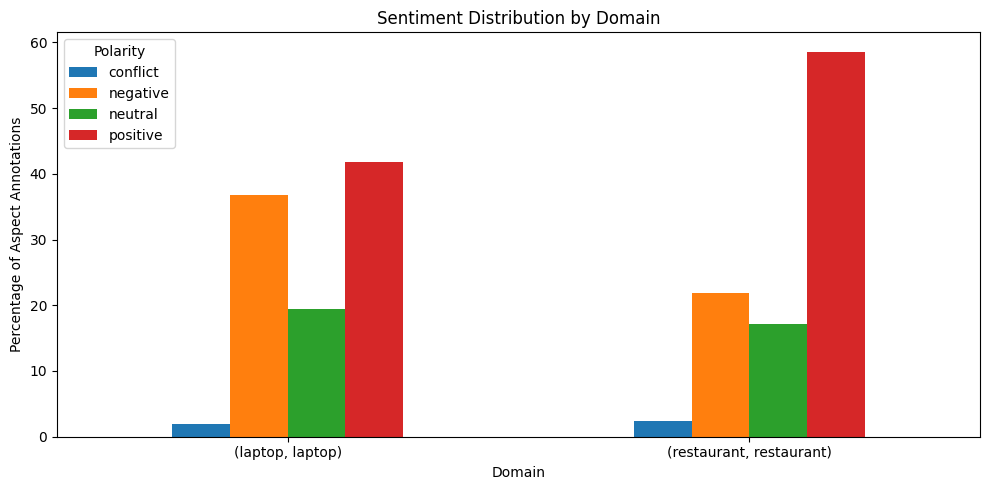


TOP 15 ASPECT TERMS - LAPTOP


,aspect_term,frequency
0,screen,58
1,price,55
2,use,53
3,battery life,52
4,battery,45
5,keyboard,43
6,programs,36
7,software,33
8,features,32
9,warranty,31



TOP 15 ASPECT TERMS - RESTAURANT


,aspect_term,frequency
0,food,357
1,service,206
2,place,64
3,prices,60
4,menu,57
5,staff,56
6,dinner,55
7,atmosphere,49
8,pizza,43
9,table,41



ASPECT TERM LENGTH STATISTICS


,count,mean,std,min,25%,50%,75%,max
domain,,,,,,,,
laptop,2358.0,1.48,0.74,1.0,1.0,1.0,2.0,6.0
restaurant,3693.0,1.39,0.94,1.0,1.0,1.0,1.0,19.0



EXACT DUPLICATE ASPECT ANNOTATIONS: 0

RESTAURANT CATEGORY DISTRIBUTION (%)


,proportion
category,
food,33.18
anecdotes/miscellaneous,30.49
service,16.08
ambience,11.61
price,8.65


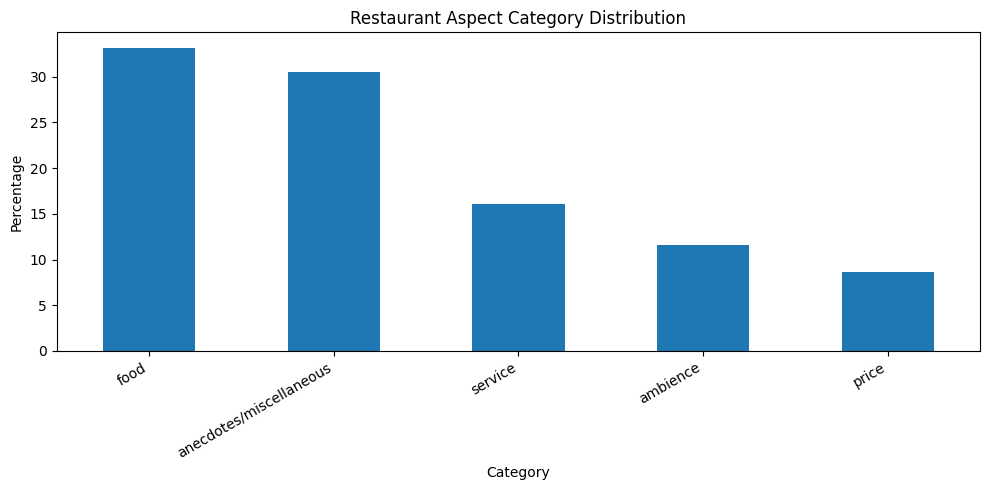

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Dataset overview
# --------------------------------------------------

print("ASPECT-TERM DATASET")
print("-" * 50)

for (domain, split), group in aspect_df.groupby(["domain", "split"]):

    print(f"\n{domain.upper()} - {split.upper()}")
    print("Total aspect annotations:", len(group))
    print("Unique sentences:", group["sentence_id"].nunique())
    print("Unique aspect terms:", group["aspect_term"].nunique())

# --------------------------------------------------
# 2. Sentiment distribution in percentages
# --------------------------------------------------

train_aspects = aspect_df[aspect_df["split"] == "train"].copy()

sentiment_distribution = (
    train_aspects.groupby(["domain", "polarity"])
    .size()
    .groupby(level=0)
    .apply(lambda x: 100 * x / x.sum())
    .unstack(fill_value=0)
)

print("\nSENTIMENT DISTRIBUTION (%)")
display(sentiment_distribution.round(2))

sentiment_distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Sentiment Distribution by Domain")
plt.ylabel("Percentage of Aspect Annotations")
plt.xlabel("Domain")
plt.xticks(rotation=0)
plt.legend(title="Polarity")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. Most frequent aspect terms
# --------------------------------------------------

for domain in ["laptop", "restaurant"]:

    domain_data = train_aspects[
        train_aspects["domain"] == domain
    ]

    print(f"\nTOP 15 ASPECT TERMS - {domain.upper()}")

    display(
        domain_data["aspect_term"]
        .value_counts()
        .head(15)
        .rename_axis("aspect_term")
        .reset_index(name="frequency")
    )

# --------------------------------------------------
# 4. Aspect term length
# --------------------------------------------------

train_aspects["aspect_length"] = (
    train_aspects["aspect_term"].str.split().str.len()
)

print("\nASPECT TERM LENGTH STATISTICS")
display(
    train_aspects.groupby("domain")["aspect_length"]
    .describe()
    .round(2)
)

# --------------------------------------------------
# 5. Duplicate annotation checks
# --------------------------------------------------

duplicate_columns = [
    "domain",
    "split",
    "sentence_id",
    "aspect_term",
    "polarity",
    "start",
    "end"
]

duplicates = aspect_df.duplicated(
    subset=duplicate_columns
).sum()

print("\nEXACT DUPLICATE ASPECT ANNOTATIONS:", duplicates)

# --------------------------------------------------
# 6. Category distribution
# --------------------------------------------------

print("\nRESTAURANT CATEGORY DISTRIBUTION (%)")

train_categories = category_df[
    category_df["split"] == "train"
].copy()

category_distribution = (
    train_categories["category"]
    .value_counts(normalize=True) * 100
)

display(category_distribution.round(2))

category_distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Restaurant Aspect Category Distribution")
plt.ylabel("Percentage")
plt.xlabel("Category")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

# Check exact sentence overlap between train and test

for domain in ["laptop", "restaurant"]:

    train_texts = set(
        aspect_df.loc[
            (aspect_df["domain"] == domain) &
            (aspect_df["split"] == "train"),
            "sentence"
        ].str.strip().str.lower()
    )

    test_texts = set(
        aspect_df.loc[
            (aspect_df["domain"] == domain) &
            (aspect_df["split"] == "test"),
            "sentence"
        ].str.strip().str.lower()
    )

    overlap = train_texts.intersection(test_texts)

    print(f"\n{domain.upper()}")
    print("Unique training sentences:", len(train_texts))
    print("Unique test sentences:", len(test_texts))
    print("Exact sentence overlap:", len(overlap))

    if overlap:
        print("Examples:")
        for sentence in list(overlap)[:5]:
            print("-", sentence)



LAPTOP
Unique training sentences: 1479
Unique test sentences: 422
Exact sentence overlap: 1
Examples:
- if you want more information on macs i suggest going to apple.com and heading towards the macbook page for more information on the applications.

RESTAURANT
Unique training sentences: 2019
Unique test sentences: 606
Exact sentence overlap: 1
Examples:
- i would definitely go back -- if only for some of those exotic martinis on the blackboard.


In [ ]:

for domain in ["laptop", "restaurant"]:

    train = aspect_df[
        (aspect_df["domain"] == domain) &
        (aspect_df["split"] == "train")
    ].copy()

    test = aspect_df[
        (aspect_df["domain"] == domain) &
        (aspect_df["split"] == "test")
    ].copy()

    # Normalize text for exact comparison
    train["normalized"] = (
        train["sentence"].str.strip().str.lower()
    )

    test["normalized"] = (
        test["sentence"].str.strip().str.lower()
    )

    overlapping_texts = (
        set(train["normalized"]) &
        set(test["normalized"])
    )

    print("\n" + "=" * 65)
    print(domain.upper(), "OVERLAP DETAILS")
    print("=" * 65)

    for text in overlapping_texts:

        print("\nSentence:")
        print(text)

        print("\nTraining annotations:")
        display(
            train[train["normalized"] == text][
                ["sentence_id", "aspect_term", "polarity"]
            ]
        )

        print("\nTest annotations:")
        display(
            test[test["normalized"] == text][
                ["sentence_id", "aspect_term", "polarity"]
            ]
        )



LAPTOP OVERLAP DETAILS

Sentence:
if you want more information on macs i suggest going to apple.com and heading towards the macbook page for more information on the applications.

Training annotations:


,sentence_id,aspect_term,polarity
995,227,applications,neutral



Test annotations:


,sentence_id,aspect_term,polarity
2574,227,applications,neutral



RESTAURANT OVERLAP DETAILS

Sentence:
i would definitely go back -- if only for some of those exotic martinis on the blackboard.

Training annotations:


,sentence_id,aspect_term,polarity
6021,1715,martinis,positive



Test annotations:


,sentence_id,aspect_term,polarity
7389,11350031#590790#3,martinis,positive


In [3]:

from sklearn.model_selection import GroupShuffleSplit

# Work on a copy; preserve the original DataFrames
model_data = aspect_df.copy()

# Normalize sentence text for leakage detection and grouping
model_data["normalized_sentence"] = (
    model_data["sentence"]
    .str.strip()
    .str.lower()
)

# Identify sentences appearing in both official splits
train_texts = set(
    model_data.loc[
        model_data["split"] == "train",
        "normalized_sentence"
    ]
)

test_texts = set(
    model_data.loc[
        model_data["split"] == "test",
        "normalized_sentence"
    ]
)

overlapping_texts = train_texts.intersection(test_texts)

print("Overlapping sentences:", len(overlapping_texts))

# Exclude overlapping training examples only
clean_train = model_data[
    (model_data["split"] == "train") &
    (~model_data["normalized_sentence"].isin(overlapping_texts))
].copy()

# Keep official test data untouched
official_test = model_data[
    model_data["split"] == "test"
].copy()

print("\nClean training annotations:", len(clean_train))
print("Official test annotations:", len(official_test))

# Create sentence-grouped train/validation splits
train_parts = []
validation_parts = []

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

for domain in ["laptop", "restaurant"]:

    domain_data = clean_train[
        clean_train["domain"] == domain
    ].copy()

    train_indices, val_indices = next(
        splitter.split(
            domain_data,
            groups=domain_data["normalized_sentence"]
        )
    )

    train_part = domain_data.iloc[train_indices].copy()
    val_part = domain_data.iloc[val_indices].copy()

    train_parts.append(train_part)
    validation_parts.append(val_part)

    # Confirm no sentence leakage
    train_groups = set(train_part["normalized_sentence"])
    val_groups = set(val_part["normalized_sentence"])

    print(f"\n{domain.upper()}")
    print("Training annotations:", len(train_part))
    print("Validation annotations:", len(val_part))
    print("Training sentences:", len(train_groups))
    print("Validation sentences:", len(val_groups))
    print("Sentence overlap:", len(train_groups & val_groups))

model_train = pd.concat(train_parts, ignore_index=True)
model_validation = pd.concat(
    validation_parts,
    ignore_index=True
)

print("\nFINAL DATASET SIZES")
print("Training:", model_train.shape)
print("Validation:", model_validation.shape)
print("Official test:", official_test.shape)


Overlapping sentences: 2

Clean training annotations: 6049
Official test annotations: 1788

LAPTOP
Training annotations: 1895
Validation annotations: 462
Training sentences: 1182
Validation sentences: 296
Sentence overlap: 0

RESTAURANT
Training annotations: 2964
Validation annotations: 728
Training sentences: 1614
Validation sentences: 404
Sentence overlap: 0

FINAL DATASET SIZES
Training: (4859, 9)
Validation: (1190, 9)
Official test: (1788, 9)


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# --------------------------------------------------
# 1. Construct aspect-conditioned input
# --------------------------------------------------

def make_model_input(df):
    return (
        df["sentence"].fillna("")
        + " [ASPECT] "
        + df["aspect_term"].fillna("")
    )


# Store fitted models and vectorizers for later experiments
baseline_models = {}
baseline_vectorizers = {}

results = []

# Consistent class ordering for evaluation
classes = ["positive", "negative", "neutral", "conflict"]

# --------------------------------------------------
# 2. Train separate models for each domain
# --------------------------------------------------

for domain in ["laptop", "restaurant"]:

    print("\n" + "=" * 70)
    print(domain.upper(), "SENTIMENT CLASSIFICATION")
    print("=" * 70)

    # Select domain-specific training and validation data
    train_df = model_train[
        model_train["domain"] == domain
    ].copy()

    val_df = model_validation[
        model_validation["domain"] == domain
    ].copy()

    X_train_text = make_model_input(train_df)
    X_val_text = make_model_input(val_df)

    y_train = train_df["polarity"]
    y_val = val_df["polarity"]

    # --------------------------------------------------
    # 3. TF-IDF feature extraction
    # --------------------------------------------------

    vectorizer = TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )

    X_train = vectorizer.fit_transform(X_train_text)
    X_val = vectorizer.transform(X_val_text)

    print("\nTF-IDF feature information")
    print("Training matrix:", X_train.shape)
    print("Validation matrix:", X_val.shape)
    print("Number of features:", len(vectorizer.vocabulary_))
    print("Training matrix non-zero values:", X_train.nnz)

    # --------------------------------------------------
    # 4. Compare ordinary and balanced Logistic Regression
    # --------------------------------------------------

    for weighting in [None, "balanced"]:

        model = LogisticRegression(
            max_iter=2000,
            class_weight=weighting,
            random_state=42
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        macro_f1 = f1_score(
            y_val,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        accuracy = accuracy_score(y_val, predictions)

        results.append({
            "domain": domain,
            "class_weight": str(weighting),
            "accuracy": accuracy,
            "macro_f1": macro_f1
        })

        print("\n" + "-" * 50)
        print("Class weighting:", weighting)
        print("Accuracy:", round(accuracy, 4))
        print("Macro-F1:", round(macro_f1, 4))

        print("\nClassification report:")
        print(
            classification_report(
                y_val,
                predictions,
                labels=classes,
                zero_division=0
            )
        )

        print("Confusion matrix:")
        cm = confusion_matrix(
            y_val,
            predictions,
            labels=classes
        )

        display(
            pd.DataFrame(
                cm,
                index=[f"Actual {c}" for c in classes],
                columns=[f"Predicted {c}" for c in classes]
            )
        )

        # Keep both fitted models
        baseline_models[(domain, str(weighting))] = model

    baseline_vectorizers[domain] = vectorizer

# --------------------------------------------------
# 5. Compare all four experiments
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("BASELINE EXPERIMENT COMPARISON")
print("=" * 70)

display(
    results_df.sort_values(
        ["domain", "macro_f1"],
        ascending=[True, False]
    ).reset_index(drop=True)
)



LAPTOP SENTIMENT CLASSIFICATION

TF-IDF feature information
Training matrix: (1895, 9293)
Validation matrix: (462, 9293)
Number of features: 9293
Training matrix non-zero values: 62342

--------------------------------------------------
Class weighting: None
Accuracy: 0.6299
Macro-F1: 0.3795

Classification report:
              precision    recall  f1-score   support

    positive       0.68      0.83      0.74       176
    negative       0.61      0.77      0.68       181
     neutral       0.33      0.05      0.09        92
    conflict       0.00      0.00      0.00        13

    accuracy                           0.63       462
   macro avg       0.40      0.41      0.38       462
weighted avg       0.56      0.63      0.57       462

Confusion matrix:


,Predicted positive,Predicted negative,Predicted neutral,Predicted conflict
Actual positive,146,28,2,0
Actual negative,33,140,8,0
Actual neutral,33,54,5,0
Actual conflict,4,9,0,0



--------------------------------------------------
Class weighting: balanced
Accuracy: 0.6299
Macro-F1: 0.4728

Classification report:
              precision    recall  f1-score   support

    positive       0.73      0.74      0.73       176
    negative       0.63      0.73      0.68       181
     neutral       0.37      0.30      0.34        92
    conflict       1.00      0.08      0.14        13

    accuracy                           0.63       462
   macro avg       0.68      0.46      0.47       462
weighted avg       0.63      0.63      0.62       462

Confusion matrix:


,Predicted positive,Predicted negative,Predicted neutral,Predicted conflict
Actual positive,130,24,22,0
Actual negative,27,132,22,0
Actual neutral,19,45,28,0
Actual conflict,2,7,3,1



RESTAURANT SENTIMENT CLASSIFICATION

TF-IDF feature information
Training matrix: (2964, 12953)
Validation matrix: (728, 12953)
Number of features: 12953
Training matrix non-zero values: 95072

--------------------------------------------------
Class weighting: None
Accuracy: 0.6552
Macro-F1: 0.3616

Classification report:
              precision    recall  f1-score   support

    positive       0.68      0.93      0.79       430
    negative       0.56      0.40      0.46       154
     neutral       0.48      0.12      0.19       123
    conflict       0.00      0.00      0.00        21

    accuracy                           0.66       728
   macro avg       0.43      0.36      0.36       728
weighted avg       0.60      0.66      0.60       728

Confusion matrix:


,Predicted positive,Predicted negative,Predicted neutral,Predicted conflict
Actual positive,401,19,10,0
Actual negative,87,61,6,0
Actual neutral,87,21,15,0
Actual conflict,13,8,0,0



--------------------------------------------------
Class weighting: balanced
Accuracy: 0.6332
Macro-F1: 0.4847

Classification report:
              precision    recall  f1-score   support

    positive       0.80      0.75      0.77       430
    negative       0.52      0.63      0.57       154
     neutral       0.31      0.30      0.31       123
    conflict       0.30      0.29      0.29        21

    accuracy                           0.63       728
   macro avg       0.48      0.49      0.48       728
weighted avg       0.64      0.63      0.64       728

Confusion matrix:


,Predicted positive,Predicted negative,Predicted neutral,Predicted conflict
Actual positive,321,49,51,9
Actual negative,27,97,28,2
Actual neutral,49,34,37,3
Actual conflict,5,8,2,6



BASELINE EXPERIMENT COMPARISON


,domain,class_weight,accuracy,macro_f1
0,laptop,balanced,0.629870,0.472828
1,laptop,None,0.629870,0.379492
2,restaurant,balanced,0.633242,0.484656
3,restaurant,None,0.655220,0.361626


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import pandas as pd

# --------------------------------------------------
# 1. Mark the target aspect using character offsets
# --------------------------------------------------

def make_marked_input(df):

    inputs = []

    for _, row in df.iterrows():

        sentence = row["sentence"]
        start = int(row["start"])
        end = int(row["end"])

        marked_sentence = (
            sentence[:start]
            + " TARGET_START "
            + sentence[start:end]
            + " TARGET_END "
            + sentence[end:]
        )

        inputs.append(marked_sentence)

    return inputs


classes = ["positive", "negative", "neutral", "conflict"]

marked_results = []
marked_models = {}
marked_vectorizers = {}

# --------------------------------------------------
# 2. Train and evaluate target-marked models
# --------------------------------------------------

for domain in ["laptop", "restaurant"]:

    print("\n" + "=" * 65)
    print(domain.upper(), "- TARGET-MARKED TF-IDF")
    print("=" * 65)

    train_df = model_train[
        model_train["domain"] == domain
    ].copy()

    val_df = model_validation[
        model_validation["domain"] == domain
    ].copy()

    X_train_text = make_marked_input(train_df)
    X_val_text = make_marked_input(val_df)

    y_train = train_df["polarity"]
    y_val = val_df["polarity"]

    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )

    X_train = vectorizer.fit_transform(X_train_text)
    X_val = vectorizer.transform(X_val_text)

    print("Training matrix:", X_train.shape)
    print("Validation matrix:", X_val.shape)

    model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)

    macro_f1 = f1_score(
        y_val,
        predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    marked_results.append({
        "domain": domain,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    })

    marked_models[domain] = model
    marked_vectorizers[domain] = vectorizer

    print("\nAccuracy:", round(accuracy, 4))
    print("Macro-F1:", round(macro_f1, 4))

    print("\nClassification report:")
    print(
        classification_report(
            y_val,
            predictions,
            labels=classes,
            zero_division=0
        )
    )

marked_results_df = pd.DataFrame(marked_results)

print("\nTARGET-MARKED EXPERIMENT RESULTS")
display(marked_results_df)



LAPTOP - TARGET-MARKED TF-IDF
Training matrix: (1895, 8807)
Validation matrix: (462, 8807)

Accuracy: 0.6494
Macro-F1: 0.494

Classification report:
              precision    recall  f1-score   support

    positive       0.76      0.75      0.76       176
    negative       0.66      0.73      0.69       181
     neutral       0.40      0.37      0.38        92
    conflict       1.00      0.08      0.14        13

    accuracy                           0.65       462
   macro avg       0.70      0.48      0.49       462
weighted avg       0.66      0.65      0.64       462


RESTAURANT - TARGET-MARKED TF-IDF
Training matrix: (2964, 12169)
Validation matrix: (728, 12169)

Accuracy: 0.6525
Macro-F1: 0.5221

Classification report:
              precision    recall  f1-score   support

    positive       0.81      0.76      0.79       430
    negative       0.51      0.62      0.56       154
     neutral       0.38      0.37      0.38       123
    conflict       0.35      0.38      0.

,domain,accuracy,macro_f1
0,laptop,0.649351,0.493961
1,restaurant,0.652473,0.522063


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

classes = ["positive", "negative", "neutral", "conflict"]

combined_results = []
combined_models = {}

for domain in ["laptop", "restaurant"]:

    train_df = model_train[model_train["domain"] == domain].copy()
    val_df = model_validation[model_validation["domain"] == domain].copy()

    # Reuse the same target-marked text representation
    X_train_text = make_marked_input(train_df)
    X_val_text = make_marked_input(val_df)

    y_train = train_df["polarity"]
    y_val = val_df["polarity"]

    # Combine word-level and character-level TF-IDF
    combined_vectorizer = FeatureUnion([
        ("word_tfidf", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            max_features=30000,
            sublinear_tf=True
        )),
        ("char_tfidf", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
            max_features=30000,
            sublinear_tf=True
        ))
    ])

    X_train = combined_vectorizer.fit_transform(X_train_text)
    X_val = combined_vectorizer.transform(X_val_text)

    model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val,
        predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    combined_results.append({
        "domain": domain,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "features": X_train.shape[1]
    })

    combined_models[domain] = {
        "model": model,
        "vectorizer": combined_vectorizer
    }

    print("=" * 65)
    print(f"{domain.upper()} - WORD + CHARACTER TF-IDF")
    print("=" * 65)
    print("Training matrix:", X_train.shape)
    print("Validation matrix:", X_val.shape)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro-F1: {macro_f1:.4f}")
    print("\nClassification report:")
    print(classification_report(
        y_val,
        predictions,
        labels=classes,
        zero_division=0
    ))

combined_results_df = pd.DataFrame(combined_results)
display(combined_results_df)


LAPTOP - WORD + CHARACTER TF-IDF
Training matrix: (1895, 26211)
Validation matrix: (462, 26211)
Accuracy: 0.6494
Macro-F1: 0.4941

Classification report:
              precision    recall  f1-score   support

    positive       0.78      0.76      0.77       176
    negative       0.66      0.72      0.69       181
     neutral       0.37      0.37      0.37        92
    conflict       1.00      0.08      0.14        13

    accuracy                           0.65       462
   macro avg       0.70      0.48      0.49       462
weighted avg       0.66      0.65      0.64       462

RESTAURANT - WORD + CHARACTER TF-IDF
Training matrix: (2964, 34507)
Validation matrix: (728, 34507)
Accuracy: 0.6676
Macro-F1: 0.5363

Classification report:
              precision    recall  f1-score   support

    positive       0.82      0.76      0.79       430
    negative       0.54      0.62      0.58       154
     neutral       0.42      0.46      0.44       123
    conflict       0.43      0.29   

,domain,accuracy,macro_f1,features
0,laptop,0.649351,0.494062,26211
1,restaurant,0.667582,0.536349,34507


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

train_df = model_train[model_train["domain"] == "laptop"].copy()
val_df = model_validation[model_validation["domain"] == "laptop"].copy()

X_train_text = make_marked_input(train_df)
X_val_text = make_marked_input(val_df)

y_train = train_df["polarity"]
y_val = val_df["polarity"]

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text)
X_val = vectorizer.transform(X_val_text)

results = []

for c_value in [0.01, 0.1, 1.0, 3.0, 10.0]:

    model = LogisticRegression(
        C=c_value,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    results.append({
        "C": c_value,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )
    })

laptop_tuning_results = pd.DataFrame(results)
display(laptop_tuning_results)


,C,accuracy,macro_f1
0,0.01,0.614719,0.506843
1,0.10,0.642857,0.514199
2,1.00,0.649351,0.493961
3,3.00,0.621212,0.465712
4,10.00,0.612554,0.453261


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

train_df = model_train[
    model_train["domain"] == "restaurant"
].copy()

val_df = model_validation[
    model_validation["domain"] == "restaurant"
].copy()

X_train_text = make_marked_input(train_df)
X_val_text = make_marked_input(val_df)

y_train = train_df["polarity"]
y_val = val_df["polarity"]

# Same word + character representation as our previous experiment
vectorizer = FeatureUnion([
    ("word_tfidf", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )),
    ("char_tfidf", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    ))
])

X_train = vectorizer.fit_transform(X_train_text)
X_val = vectorizer.transform(X_val_text)

results = []

for c_value in [0.01, 0.1, 1.0, 3.0, 10.0]:

    model = LogisticRegression(
        C=c_value,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    results.append({
        "C": c_value,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )
    })

restaurant_tuning_results = pd.DataFrame(results)
display(restaurant_tuning_results)


,C,accuracy,macro_f1
0,0.01,0.605769,0.511224
1,0.10,0.627747,0.512796
2,1.00,0.667582,0.536349
3,3.00,0.662088,0.500632
4,10.00,0.660714,0.498957


In [4]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [5]:
!pip install -q transformers datasets accelerate evaluate

In [6]:
import torch
import transformers
import datasets
import accelerate

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
Datasets: 4.8.5
Accelerate: 1.15.0
Selected device: cuda
GPU: Tesla T4


In [7]:
from transformers import AutoTokenizer

MODEL_CHECKPOINT = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

sample_sentence = "The battery is excellent, but the screen is terrible."
sample_aspect = "battery"

encoded = tokenizer(
    sample_sentence,
    sample_aspect,
    truncation=True,
    max_length=128,
    padding="max_length",
    return_tensors="pt"
)

print("Input IDs shape:", encoded["input_ids"].shape)
print("Attention mask shape:", encoded["attention_mask"].shape)

print("\nDecoded input:")
print(tokenizer.decode(encoded["input_ids"][0], skip_special_tokens=False))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Input IDs shape: torch.Size([1, 128])
Attention mask shape: torch.Size([1, 128])

Decoded input:
[CLS] the battery is excellent, but the screen is terrible. [SEP] battery [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [9]:
from torch.utils.data import Dataset
import torch

LABEL2ID = {
    "positive": 0,
    "negative": 1,
    "neutral": 2,
    "conflict": 3
}

ID2LABEL = {v: k for k, v in LABEL2ID.items()}


class ABSADataset(Dataset):

    def __init__(self, dataframe, tokenizer, max_length=128):

        self.sentences = dataframe["sentence"].fillna("").tolist()
        self.aspects = dataframe["aspect_term"].fillna("").tolist()

        self.labels = [
            LABEL2ID[label]
            for label in dataframe["polarity"]
        ]

        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            self.sentences[idx],
            self.aspects[idx],
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long)
        }


In [10]:
laptop_train_df = model_train[
    model_train["domain"] == "laptop"
].copy()

laptop_val_df = model_validation[
    model_validation["domain"] == "laptop"
].copy()

laptop_train_dataset = ABSADataset(
    laptop_train_df, tokenizer
)

laptop_val_dataset = ABSADataset(
    laptop_val_df, tokenizer
)

print("Laptop training examples:", len(laptop_train_dataset))
print("Laptop validation examples:", len(laptop_val_dataset))

sample = laptop_train_dataset[0]

print("\nTensor shapes:")
print("Input IDs:", sample["input_ids"].shape)
print("Attention mask:", sample["attention_mask"].shape)
print("Label:", sample["labels"])
print("Decoded:", tokenizer.decode(sample["input_ids"]))

Laptop training examples: 1895
Laptop validation examples: 462

Tensor shapes:
Input IDs: torch.Size([128])
Attention mask: torch.Size([128])
Label: tensor(0)
Decoded: [CLS] it is of high quality, has a killer gui, is extremely stable, is highly expandable, is bundled with lots of very good applications, is easy to use, and is absolutely gorgeous. [SEP] quality [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [11]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    laptop_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    laptop_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

batch = next(iter(train_loader))

for key, value in batch.items():
    print(key, value.shape)

Training batches: 119
Validation batches: 29
input_ids torch.Size([16, 128])
attention_mask torch.Size([16, 128])
labels torch.Size([16])


In [12]:
from transformers import (
    AutoModelForSequenceClassification
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=4,
    id2label=ID2LABEL,
    label2id=LABEL2ID
)

model = model.to(device)

print("Model loaded successfully!")
print("Device:", next(model.parameters()).device)
print("Number of labels:", model.config.num_labels)
print("Total parameters:", sum(
    p.numel() for p in model.parameters()
))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Device: cuda:0
Number of labels: 4
Total parameters: 66956548


In [13]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight

train_labels = np.array(laptop_train_dataset.labels)

classes = np.array([0, 1, 2, 3])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

for label_id, weight in enumerate(class_weights):
    print(
        ID2LABEL[label_id],
        "->",
        round(weight.item(), 3)
    )

positive -> 0.584
negative -> 0.692
neutral -> 1.291
conflict -> 14.805


In [14]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 2e-5)
print("Weight decay:", 0.01)
print("Loss function:", criterion.__class__.__name__)

Optimizer: AdamW
Learning rate: 2e-05
Weight decay: 0.01
Loss function: CrossEntropyLoss


In [16]:
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

def train_one_epoch(model, loader, optimizer, criterion):

    model.train()
    total_loss = 0

    progress_bar = tqdm(loader, desc="Training")

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs.logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=loss.item()
        )

    return total_loss / len(loader)

In [17]:
def evaluate_model(model, loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in tqdm(loader, desc="Validation"):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions = torch.argmax(
                outputs.logits, dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1, all_labels, all_predictions

In [18]:
import copy

EPOCHS = 3

best_macro_f1 = -1
best_model_state = None

history = []

for epoch in range(EPOCHS):

    print(f"\n{'='*45}")
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"{'='*45}")

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_accuracy, val_macro_f1, y_true, y_pred = (
        evaluate_model(model, val_loader)
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    print(f"\nTraining loss: {train_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro-F1: {val_macro_f1:.4f}")

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2, 3],
            target_names=[
                "positive", "negative",
                "neutral", "conflict"
            ],
            zero_division=0
        )
    )

    if val_macro_f1 > best_macro_f1:

        best_macro_f1 = val_macro_f1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        print("New best model saved in memory!")


Epoch 1/3


Training:   0%|          | 0/119 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]


Training loss: 1.1391
Validation accuracy: 0.6840
Validation Macro-F1: 0.5050

Classification report:
              precision    recall  f1-score   support

    positive       0.77      0.76      0.76       176
    negative       0.78      0.69      0.73       181
     neutral       0.45      0.63      0.52        92
    conflict       0.00      0.00      0.00        13

    accuracy                           0.68       462
   macro avg       0.50      0.52      0.50       462
weighted avg       0.69      0.68      0.68       462

New best model saved in memory!

Epoch 2/3


Training:   0%|          | 0/119 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]


Training loss: 0.8591
Validation accuracy: 0.7078
Validation Macro-F1: 0.5344

Classification report:
              precision    recall  f1-score   support

    positive       0.81      0.79      0.80       176
    negative       0.71      0.81      0.76       181
     neutral       0.53      0.45      0.48        92
    conflict       0.14      0.08      0.10        13

    accuracy                           0.71       462
   macro avg       0.55      0.53      0.53       462
weighted avg       0.70      0.71      0.70       462

New best model saved in memory!

Epoch 3/3


Training:   0%|          | 0/119 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]


Training loss: 0.6176
Validation accuracy: 0.7078
Validation Macro-F1: 0.6080

Classification report:
              precision    recall  f1-score   support

    positive       0.84      0.80      0.82       176
    negative       0.80      0.67      0.73       181
     neutral       0.53      0.63      0.57        92
    conflict       0.22      0.54      0.31        13

    accuracy                           0.71       462
   macro avg       0.60      0.66      0.61       462
weighted avg       0.74      0.71      0.72       462

New best model saved in memory!


In [19]:
from pathlib import Path

# Restore the best validation checkpoint
model.load_state_dict(best_model_state)

# Persistent Google Drive location
MODEL_DIR = (
    PROJECT_DIR
    / "trained_models"
    / "distilbert_laptop"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save model weights and configuration
model.save_pretrained(MODEL_DIR)

# Save tokenizer
tokenizer.save_pretrained(MODEL_DIR)

# Save training history
import pandas as pd

pd.DataFrame(history).to_csv(
    MODEL_DIR / "training_history.csv",
    index=False
)

print("Best Macro-F1:", best_macro_f1)
print("Model saved at:", MODEL_DIR)
print("Files:", [p.name for p in MODEL_DIR.iterdir()])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best Macro-F1: 0.6079656763602193
Model saved at: /content/drive/MyDrive/SignalLens/trained_models/distilbert_laptop
Files: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_history.csv']


In [20]:
restaurant_train_df = model_train[
    model_train["domain"] == "restaurant"
].copy()

restaurant_val_df = model_validation[
    model_validation["domain"] == "restaurant"
].copy()

restaurant_train_dataset = ABSADataset(
    restaurant_train_df, tokenizer
)

restaurant_val_dataset = ABSADataset(
    restaurant_val_df, tokenizer
)

print("Restaurant training examples:", len(restaurant_train_dataset))
print("Restaurant validation examples:", len(restaurant_val_dataset))

Restaurant training examples: 2964
Restaurant validation examples: 728


In [21]:
restaurant_train_loader = DataLoader(
    restaurant_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

restaurant_val_loader = DataLoader(
    restaurant_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Calculate weights using restaurant training labels only
restaurant_labels = np.array(
    restaurant_train_dataset.labels
)

restaurant_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2, 3]),
    y=restaurant_labels
)

restaurant_class_weights = torch.tensor(
    restaurant_class_weights,
    dtype=torch.float32
).to(device)

print("Training batches:", len(restaurant_train_loader))
print("Validation batches:", len(restaurant_val_loader))

print("\nRestaurant class weights:")
for label_id, weight in enumerate(restaurant_class_weights):
    print(ID2LABEL[label_id], "->", round(weight.item(), 3))

Training batches: 186
Validation batches: 46

Restaurant class weights:
positive -> 0.428
negative -> 1.138
neutral -> 1.453
conflict -> 10.586


In [22]:
restaurant_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=4,
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to(device)

restaurant_optimizer = AdamW(
    restaurant_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

restaurant_criterion = torch.nn.CrossEntropyLoss(
    weight=restaurant_class_weights
)

print("Restaurant model initialized.")
print("Parameters:", sum(
    p.numel() for p in restaurant_model.parameters()
))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Restaurant model initialized.
Parameters: 66956548


In [23]:
RESTAURANT_EPOCHS = 3

restaurant_best_macro_f1 = -1
restaurant_best_model_state = None
restaurant_history = []

for epoch in range(RESTAURANT_EPOCHS):

    print(f"\n{'='*45}")
    print(f"Restaurant Epoch {epoch + 1}/{RESTAURANT_EPOCHS}")
    print(f"{'='*45}")

    train_loss = train_one_epoch(
        restaurant_model,
        restaurant_train_loader,
        restaurant_optimizer,
        restaurant_criterion
    )

    val_accuracy, val_macro_f1, y_true, y_pred = (
        evaluate_model(
            restaurant_model,
            restaurant_val_loader
        )
    )

    restaurant_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    print(f"\nTraining loss: {train_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro-F1: {val_macro_f1:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            "positive", "negative",
            "neutral", "conflict"
        ],
        zero_division=0
    ))

    if val_macro_f1 > restaurant_best_macro_f1:

        restaurant_best_macro_f1 = val_macro_f1

        restaurant_best_model_state = copy.deepcopy(
            restaurant_model.state_dict()
        )

        print("New best restaurant model saved in memory!")


Restaurant Epoch 1/3


Training:   0%|          | 0/186 [00:00<?, ?it/s]

Validation:   0%|          | 0/46 [00:00<?, ?it/s]


Training loss: 1.1494
Validation accuracy: 0.6511
Validation Macro-F1: 0.4531

Classification report:
              precision    recall  f1-score   support

    positive       0.87      0.74      0.80       430
    negative       0.50      0.68      0.57       154
     neutral       0.35      0.40      0.37       123
    conflict       0.12      0.05      0.07        21

    accuracy                           0.65       728
   macro avg       0.46      0.47      0.45       728
weighted avg       0.68      0.65      0.66       728

New best restaurant model saved in memory!

Restaurant Epoch 2/3


Training:   0%|          | 0/186 [00:00<?, ?it/s]

Validation:   0%|          | 0/46 [00:00<?, ?it/s]


Training loss: 0.8396
Validation accuracy: 0.6662
Validation Macro-F1: 0.5401

Classification report:
              precision    recall  f1-score   support

    positive       0.88      0.74      0.81       430
    negative       0.59      0.64      0.61       154
     neutral       0.36      0.46      0.40       123
    conflict       0.25      0.52      0.34        21

    accuracy                           0.67       728
   macro avg       0.52      0.59      0.54       728
weighted avg       0.71      0.67      0.68       728

New best restaurant model saved in memory!

Restaurant Epoch 3/3


Training:   0%|          | 0/186 [00:00<?, ?it/s]

Validation:   0%|          | 0/46 [00:00<?, ?it/s]


Training loss: 0.6519
Validation accuracy: 0.7033
Validation Macro-F1: 0.5639

Classification report:
              precision    recall  f1-score   support

    positive       0.86      0.80      0.83       430
    negative       0.67      0.66      0.66       154
     neutral       0.47      0.41      0.44       123
    conflict       0.21      0.67      0.32        21

    accuracy                           0.70       728
   macro avg       0.55      0.64      0.56       728
weighted avg       0.74      0.70      0.71       728

New best restaurant model saved in memory!


In [24]:
# Restore the best restaurant checkpoint
restaurant_model.load_state_dict(
    restaurant_best_model_state
)

RESTAURANT_MODEL_DIR = (
    PROJECT_DIR
    / "trained_models"
    / "distilbert_restaurant"
)

RESTAURANT_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

restaurant_model.save_pretrained(
    RESTAURANT_MODEL_DIR
)

tokenizer.save_pretrained(
    RESTAURANT_MODEL_DIR
)

pd.DataFrame(restaurant_history).to_csv(
    RESTAURANT_MODEL_DIR / "training_history.csv",
    index=False
)

print("Best restaurant Macro-F1:", restaurant_best_macro_f1)
print("Saved at:", RESTAURANT_MODEL_DIR)
print("Files:", [p.name for p in RESTAURANT_MODEL_DIR.iterdir()])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best restaurant Macro-F1: 0.5638800260178864
Saved at: /content/drive/MyDrive/SignalLens/trained_models/distilbert_restaurant
Files: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_history.csv']


In [25]:
laptop_test_df = official_test[
    official_test["domain"] == "laptop"
].copy()

restaurant_test_df = official_test[
    official_test["domain"] == "restaurant"
].copy()

laptop_test_dataset = ABSADataset(
    laptop_test_df, tokenizer
)

restaurant_test_dataset = ABSADataset(
    restaurant_test_df, tokenizer
)

laptop_test_loader = DataLoader(
    laptop_test_dataset,
    batch_size=16,
    shuffle=False
)

restaurant_test_loader = DataLoader(
    restaurant_test_dataset,
    batch_size=16,
    shuffle=False
)

print("Laptop test examples:", len(laptop_test_dataset))
print("Restaurant test examples:", len(restaurant_test_dataset))

Laptop test examples: 654
Restaurant test examples: 1134


In [26]:
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Load the saved laptop model
laptop_model = AutoModelForSequenceClassification.from_pretrained(
    PROJECT_DIR / "trained_models" / "distilbert_laptop"
).to(device)

# Load the saved restaurant model
restaurant_model = AutoModelForSequenceClassification.from_pretrained(
    PROJECT_DIR / "trained_models" / "distilbert_restaurant"
).to(device)

# Evaluate laptop model
laptop_accuracy, laptop_macro_f1, laptop_y_true, laptop_y_pred = (
    evaluate_model(laptop_model, laptop_test_loader)
)

# Evaluate restaurant model
restaurant_accuracy, restaurant_macro_f1, restaurant_y_true, restaurant_y_pred = (
    evaluate_model(restaurant_model, restaurant_test_loader)
)

print("\n========== LAPTOP TEST RESULTS ==========")
print("Accuracy:", round(laptop_accuracy, 4))
print("Macro-F1:", round(laptop_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    laptop_y_true,
    laptop_y_pred,
    labels=[0, 1, 2, 3],
    target_names=["positive", "negative", "neutral", "conflict"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(laptop_y_true, laptop_y_pred, labels=[0, 1, 2, 3]))


print("\n========== RESTAURANT TEST RESULTS ==========")
print("Accuracy:", round(restaurant_accuracy, 4))
print("Macro-F1:", round(restaurant_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    restaurant_y_true,
    restaurant_y_pred,
    labels=[0, 1, 2, 3],
    target_names=["positive", "negative", "neutral", "conflict"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(restaurant_y_true, restaurant_y_pred, labels=[0, 1, 2, 3]))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Validation:   0%|          | 0/41 [00:00<?, ?it/s]

Validation:   0%|          | 0/71 [00:00<?, ?it/s]


========== LAPTOP TEST RESULTS ==========
Accuracy: 0.7431
Macro-F1: 0.6379

Classification Report:
              precision    recall  f1-score   support

    positive       0.90      0.81      0.85       341
    negative       0.65      0.70      0.68       128
     neutral       0.68      0.64      0.66       169
    conflict       0.24      0.75      0.36        16

    accuracy                           0.74       654
   macro avg       0.62      0.73      0.64       654
weighted avg       0.78      0.74      0.76       654


Confusion Matrix:
[[276  14  26  25]
 [  7  90  23   8]
 [ 23  33 108   5]
 [  2   1   1  12]]

========== RESTAURANT TEST RESULTS ==========
Accuracy: 0.8025
Macro-F1: 0.6157

Classification Report:
              precision    recall  f1-score   support

    positive       0.87      0.92      0.89       728
    negative       0.81      0.71      0.76       196
     neutral       0.69      0.47      0.56       196
    conflict       0.16      0.64      0.25   

In [27]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import classification_report

EVALUATION_DIR = PROJECT_DIR / "evaluation"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = ["positive", "negative", "neutral", "conflict"]

def create_error_analysis(df, y_true, y_pred, domain):
    results = df[[
        "sentence_id", "sentence", "aspect_term", "polarity"
    ]].copy()

    results["predicted_polarity"] = [
        LABEL_NAMES[int(pred)] for pred in y_pred
    ]

    results["correct"] = (
        results["polarity"] == results["predicted_polarity"]
    )

    results["domain"] = domain

    return results


# Create prediction-level results
laptop_results = create_error_analysis(
    laptop_test_df,
    laptop_y_true,
    laptop_y_pred,
    "laptop"
)

restaurant_results = create_error_analysis(
    restaurant_test_df,
    restaurant_y_true,
    restaurant_y_pred,
    "restaurant"
)

# Combine both domains
all_results = pd.concat(
    [laptop_results, restaurant_results],
    ignore_index=True
)

# Extract incorrect predictions
errors = all_results[
    all_results["correct"] == False
].copy()

# Save detailed predictions and errors
all_results.to_csv(
    EVALUATION_DIR / "official_test_predictions.csv",
    index=False
)

errors.to_csv(
    EVALUATION_DIR / "misclassified_examples.csv",
    index=False
)

# Save summary metrics
summary = pd.DataFrame([
    {
        "domain": "laptop",
        "accuracy": laptop_accuracy,
        "macro_f1": laptop_macro_f1,
        "test_examples": len(laptop_test_df)
    },
    {
        "domain": "restaurant",
        "accuracy": restaurant_accuracy,
        "macro_f1": restaurant_macro_f1,
        "test_examples": len(restaurant_test_df)
    }
])

summary.to_csv(
    EVALUATION_DIR / "official_test_metrics.csv",
    index=False
)

# Save classification reports
for domain, y_true, y_pred in [
    ("laptop", laptop_y_true, laptop_y_pred),
    ("restaurant", restaurant_y_true, restaurant_y_pred)
]:
    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=LABEL_NAMES,
        zero_division=0,
        output_dict=True
    )

    pd.DataFrame(report).transpose().to_csv(
        EVALUATION_DIR / f"{domain}_classification_report.csv"
    )

print("Evaluation files saved at:", EVALUATION_DIR)
print("\nTotal test examples:", len(all_results))
print("Correct predictions:", all_results["correct"].sum())
print("Incorrect predictions:", len(errors))

print("\nErrors by domain:")
print(errors["domain"].value_counts())

print("\nErrors by actual sentiment:")
print(errors["polarity"].value_counts())

print("\nErrors by actual vs predicted sentiment:")
print(
    errors.groupby(
        ["polarity", "predicted_polarity"]
    ).size().sort_values(ascending=False)
)

Evaluation files saved at: /content/drive/MyDrive/SignalLens/evaluation

Total test examples: 1788
Correct predictions: 1396
Incorrect predictions: 392

Errors by domain:
domain
restaurant    224
laptop        168
Name: count, dtype: int64

Errors by actual sentiment:
polarity
neutral     164
positive    124
negative     95
conflict      9
Name: count, dtype: int64

Errors by actual vs predicted sentiment:
polarity  predicted_polarity
neutral   positive              96
          negative              57
positive  conflict              54
          neutral               49
negative  neutral               41
          positive              32
          conflict              22
positive  negative              21
neutral   conflict              11
conflict  positive               5
          negative               2
          neutral                2
dtype: int64


In [28]:
# Show 15 randomly selected misclassified examples
pd.set_option("display.max_colwidth", 150)

errors.sample(
    n=min(15, len(errors)),
    random_state=42
)[[
    "domain",
    "sentence",
    "aspect_term",
    "polarity",
    "predicted_polarity"
]]

,domain,sentence,aspect_term,polarity,predicted_polarity
376,laptop,"Having heard from friends and family about how reliable a Mac product is, I never expected to have an application crash within the first month, bu...",application,negative,positive
1367,restaurant,The space is traditional in feel.,space,neutral,positive
1259,restaurant,"Their twist on pizza is heatlhy, but full of flavor.",twist on pizza,positive,conflict
307,laptop,It wakes in less than a second when I open the lid.,wakes,positive,neutral
1761,restaurant,How can they survive serving mediocre food at exorbitant prices?!,food,neutral,negative
895,restaurant,We started with the scallops and asparagus and also had the soft shell crab as well as the cheese plate.,soft shell crab,neutral,positive
238,laptop,USB3 Peripherals are noticably less expensive than the ThunderBolt ones.,USB3 Peripherals,positive,negative
1212,restaurant,There's candlelight and music.,music,neutral,positive
597,laptop,i have dropped mine a couple times with only a slim plastic case covering it.,slim plastic case,neutral,negative
497,laptop,"However, the experience was great since the OS does not become unstable and the application will simply shutdown and reopen.",application,positive,conflict


In [30]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import xml.etree.ElementTree as ET

PROJECT_DIR = Path(
    "/content/drive/MyDrive/SignalLens"
)

RAW_DIR = PROJECT_DIR / "datasets/semeval2014/raw"

PROCESSED_DIR = (
    PROJECT_DIR / "datasets/semeval2014/processed"
)

print("Project directory:", PROJECT_DIR)
print("Raw directory exists:", RAW_DIR.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/SignalLens
Raw directory exists: True


In [31]:
import xml.etree.ElementTree as ET

xml_path = (
    RAW_DIR
    / "laptops"
    / "Laptop_Train_v2.xml"
)

tree = ET.parse(xml_path)
root = tree.getroot()

# Inspect one sentence with aspect annotations
for sentence in root.findall(".//sentence"):
    text = sentence.findtext("text", default="")

    aspect_terms = sentence.find("aspectTerms")

    if aspect_terms is not None:
        aspects = aspect_terms.findall("aspectTerm")

        if aspects:
            print("Sentence ID:", sentence.get("id"))
            print("Text:", text)

            for aspect in aspects:
                print({
                    "term": aspect.get("term"),
                    "from": aspect.get("from"),
                    "to": aspect.get("to"),
                    "polarity": aspect.get("polarity")
                })

            break

# Count sentences with and without aspect annotations
total_sentences = len(root.findall(".//sentence"))

sentences_with_aspects = sum(
    1
    for sentence in root.findall(".//sentence")
    if sentence.find("aspectTerms") is not None
    and sentence.find("aspectTerms").findall("aspectTerm")
)

print("\nTotal sentences:", total_sentences)
print("Sentences with aspects:", sentences_with_aspects)
print("Sentences without aspects:", total_sentences - sentences_with_aspects)

Sentence ID: 2339
Text: I charge it at night and skip taking the cord with me because of the good battery life.
{'term': 'cord', 'from': '41', 'to': '45', 'polarity': 'neutral'}
{'term': 'battery life', 'from': '74', 'to': '86', 'polarity': 'positive'}

Total sentences: 3045
Sentences with aspects: 1488
Sentences without aspects: 1557


In [32]:
import xml.etree.ElementTree as ET
import pandas as pd

def parse_ate_xml(xml_path, domain, split):

    tree = ET.parse(xml_path)
    root = tree.getroot()

    records = []

    for sentence in root.findall(".//sentence"):

        sentence_id = sentence.get("id")
        text = sentence.findtext("text", default="")

        aspect_terms = sentence.find("aspectTerms")

        aspects = []

        if aspect_terms is not None:
            for aspect in aspect_terms.findall("aspectTerm"):

                aspects.append({
                    "term": aspect.get("term"),
                    "start": int(aspect.get("from")),
                    "end": int(aspect.get("to")),
                    "polarity": aspect.get("polarity")
                })

        records.append({
            "domain": domain,
            "split": split,
            "sentence_id": sentence_id,
            "sentence": text,
            "aspects": aspects
        })

    return pd.DataFrame(records)


# Parse laptop training data
laptop_ate_train = parse_ate_xml(
    RAW_DIR / "laptops" / "Laptop_Train_v2.xml",
    "laptop",
    "train"
)

# Parse restaurant training data
restaurant_ate_train = parse_ate_xml(
    RAW_DIR / "restaurants" / "Restaurants_Train_v2.xml",
    "restaurant",
    "train"
)

# Combine both domains
ate_train_df = pd.concat(
    [laptop_ate_train, restaurant_ate_train],
    ignore_index=True
)

print("Combined dataset shape:", ate_train_df.shape)

print("\nDomain distribution:")
print(ate_train_df["domain"].value_counts())

print("\nSentences with aspects:")
print(
    ate_train_df["aspects"].apply(len).gt(0).sum()
)

print("\nSentences without aspects:")
print(
    ate_train_df["aspects"].apply(len).eq(0).sum()
)

print("\nSample:")
display(
    ate_train_df[
        ate_train_df["sentence_id"] == "2339"
    ][["domain", "sentence", "aspects"]]
)

Combined dataset shape: (6086, 5)

Domain distribution:
domain
laptop        3045
restaurant    3041
Name: count, dtype: int64

Sentences with aspects:
3509

Sentences without aspects:
2577

Sample:


,domain,sentence,aspects
0,laptop,I charge it at night and skip taking the cord with me because of the good battery life.,"[{'term': 'cord', 'start': 41, 'end': 45, 'polarity': 'neutral'}, {'term': 'battery life', 'start': 74, 'end': 86, 'polarity': 'positive'}]"


In [33]:
total_aspects = 0
valid_aspects = 0
invalid_aspects = []

for _, row in ate_train_df.iterrows():

    sentence = row["sentence"]

    for aspect in row["aspects"]:

        total_aspects += 1

        start = aspect["start"]
        end = aspect["end"]
        term = aspect["term"]

        extracted_text = sentence[start:end]

        if (
            0 <= start < end <= len(sentence)
            and extracted_text == term
        ):
            valid_aspects += 1

        else:
            invalid_aspects.append({
                "domain": row["domain"],
                "sentence_id": row["sentence_id"],
                "sentence": sentence,
                "annotated_term": term,
                "extracted_text": extracted_text,
                "start": start,
                "end": end
            })

print("Total aspect annotations:", total_aspects)
print("Valid annotations:", valid_aspects)
print("Invalid annotations:", len(invalid_aspects))

if invalid_aspects:
    display(pd.DataFrame(invalid_aspects).head(10))

Total aspect annotations: 6051
Valid annotations: 6051
Invalid annotations: 0


In [34]:
from transformers import AutoTokenizer

MODEL_CHECKPOINT = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_CHECKPOINT
)

BIO_LABELS = {
    "O": 0,
    "B-ASPECT": 1,
    "I-ASPECT": 2
}

ID2BIO = {
    value: key
    for key, value in BIO_LABELS.items()
}

print("Tokenizer loaded:", MODEL_CHECKPOINT)
print("BIO labels:", BIO_LABELS)

Tokenizer loaded: distilbert/distilbert-base-uncased
BIO labels: {'O': 0, 'B-ASPECT': 1, 'I-ASPECT': 2}


In [36]:
def create_bio_labels(row, tokenizer):

    sentence = row["sentence"]
    aspects = row["aspects"]

    encoding = tokenizer(
        sentence,
        return_offsets_mapping=True,
        truncation=False
    )

    offsets = encoding["offset_mapping"]
    labels = []

    for token_start, token_end in offsets:

        if token_start == token_end:
            labels.append(-100)
            continue

        token_label = "O"

        for aspect in aspects:

            aspect_start = aspect["start"]
            aspect_end = aspect["end"]

            if (
                token_start < aspect_end
                and token_end > aspect_start
            ):

                if token_start == aspect_start:
                    token_label = "B-ASPECT"
                else:
                    token_label = "I-ASPECT"

                break

        labels.append(BIO_LABELS[token_label])

    return encoding, labels

In [37]:
sample_row = ate_train_df[
    ate_train_df["sentence_id"] == "2339"
].iloc[0]

encoding, labels = create_bio_labels(
    sample_row,
    tokenizer
)

tokens = tokenizer.convert_ids_to_tokens(
    encoding["input_ids"]
)

for token, label in zip(tokens, labels):

    label_name = (
        "IGNORED"
        if label == -100
        else ID2BIO[label]
    )

    print(f"{token:15} {label_name}")

[CLS]           IGNORED
i               O
charge          O
it              O
at              O
night           O
and             O
skip            O
taking          O
the             O
cord            B-ASPECT
with            O
me              O
because         O
of              O
the             O
good            O
battery         B-ASPECT
life            I-ASPECT
.               O
[SEP]           IGNORED


In [38]:
alignment_errors = []
total_tokens = 0
total_aspect_tokens = 0

for idx, row in ate_train_df.iterrows():

    encoding, labels = create_bio_labels(
        row,
        tokenizer
    )

    tokens = tokenizer.convert_ids_to_tokens(
        encoding["input_ids"]
    )

    total_tokens += len(tokens)

    predicted_aspect_count = sum(
        label in [BIO_LABELS["B-ASPECT"], BIO_LABELS["I-ASPECT"]]
        for label in labels
    )

    total_aspect_tokens += predicted_aspect_count

    # Every annotated aspect should have a B-ASPECT token
    expected_aspects = len(row["aspects"])

    actual_begin_tokens = sum(
        label == BIO_LABELS["B-ASPECT"]
        for label in labels
    )

    if expected_aspects != actual_begin_tokens:

        alignment_errors.append({
            "index": idx,
            "sentence": row["sentence"],
            "expected_aspects": expected_aspects,
            "actual_B_tokens": actual_begin_tokens
        })

print("Total sentences:", len(ate_train_df))
print("Total tokens:", total_tokens)
print("Aspect tokens:", total_aspect_tokens)
print("Alignment errors:", len(alignment_errors))

if alignment_errors:
    display(pd.DataFrame(alignment_errors).head(10))

Total sentences: 6086
Total tokens: 118555
Aspect tokens: 10671
Alignment errors: 0


In [39]:
from sklearn.model_selection import GroupShuffleSplit

# Normalize sentence text for grouping
ate_train_df["normalized_sentence"] = (
    ate_train_df["sentence"]
    .str.strip()
    .str.lower()
)

# Check duplicate sentences
duplicate_count = ate_train_df.duplicated(
    subset=["domain", "normalized_sentence"]
).sum()

print("Duplicate sentence rows:", duplicate_count)

# Group-aware split, separately for each domain
train_parts = []
validation_parts = []

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

for domain in ["laptop", "restaurant"]:

    domain_df = ate_train_df[
        ate_train_df["domain"] == domain
    ].copy()

    train_idx, val_idx = next(
        splitter.split(
            domain_df,
            groups=domain_df["normalized_sentence"]
        )
    )

    train_parts.append(
        domain_df.iloc[train_idx].copy()
    )

    validation_parts.append(
        domain_df.iloc[val_idx].copy()
    )

ate_model_train = pd.concat(
    train_parts,
    ignore_index=True
)

ate_model_validation = pd.concat(
    validation_parts,
    ignore_index=True
)

# Verify no sentence overlap
train_groups = set(
    ate_model_train["normalized_sentence"]
)

validation_groups = set(
    ate_model_validation["normalized_sentence"]
)

print("\nTraining sentences:", len(ate_model_train))
print("Validation sentences:", len(ate_model_validation))

print(
    "Sentence overlap:",
    len(train_groups.intersection(validation_groups))
)

print("\nTraining distribution:")
print(ate_model_train["domain"].value_counts())

print("\nValidation distribution:")
print(ate_model_validation["domain"].value_counts())

Duplicate sentence rows: 27

Training sentences: 4865
Validation sentences: 1221
Sentence overlap: 0

Training distribution:
domain
laptop        2435
restaurant    2430
Name: count, dtype: int64

Validation distribution:
domain
restaurant    611
laptop        610
Name: count, dtype: int64


In [41]:
MAX_LENGTH = 128

def prepare_ate_example(row, tokenizer):

    sentence = row["sentence"]
    aspects = row["aspects"]

    # Tokenize the sentence
    encoding = tokenizer(
        sentence,
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length",
        return_offsets_mapping=True
    )

    offsets = encoding["offset_mapping"]

    labels = []

    for token_start, token_end in offsets:

        # Ignore special tokens and padding
        if token_start == token_end:
            labels.append(-100)
            continue

        token_label = "O"

        for aspect in aspects:

            aspect_start = aspect["start"]
            aspect_end = aspect["end"]

            if (
                token_start < aspect_end
                and token_end > aspect_start
            ):

                if token_start == aspect_start:
                    token_label = "B-ASPECT"
                else:
                    token_label = "I-ASPECT"

                break

        labels.append(BIO_LABELS[token_label])

    encoding.pop("offset_mapping")

    encoding["labels"] = labels

    return encoding

In [42]:
sample = ate_model_train[
    ate_model_train["sentence_id"] == "2339"
].iloc[0]

prepared = prepare_ate_example(
    sample,
    tokenizer
)

tokens = tokenizer.convert_ids_to_tokens(
    prepared["input_ids"]
)

for token, label in zip(tokens, prepared["labels"]):

    if label == -100:
        label_name = "IGNORED"
    else:
        label_name = ID2BIO[label]

    if token in ["[PAD]"]:
        continue

    print(f"{token:15} {label_name}")

[CLS]           IGNORED
i               O
charge          O
it              O
at              O
night           O
and             O
skip            O
taking          O
the             O
cord            B-ASPECT
with            O
me              O
because         O
of              O
the             O
good            O
battery         B-ASPECT
life            I-ASPECT
.               O
[SEP]           IGNORED


In [43]:
def get_token_lengths(df, tokenizer):
    return df["sentence"].apply(
        lambda sentence: len(
            tokenizer(
                sentence,
                truncation=False,
                add_special_tokens=True
            )["input_ids"]
        )
    )

train_lengths = get_token_lengths(
    ate_model_train, tokenizer
)

validation_lengths = get_token_lengths(
    ate_model_validation, tokenizer
)

all_lengths = pd.concat(
    [train_lengths, validation_lengths]
)

print("Maximum token length:", all_lengths.max())
print("95th percentile:", all_lengths.quantile(0.95))
print("99th percentile:", all_lengths.quantile(0.99))
print("Sentences exceeding 128 tokens:", (all_lengths > 128).sum())
print("Sentences exceeding 256 tokens:", (all_lengths > 256).sum())

Maximum token length: 91
95th percentile: 38.0
99th percentile: 54.0
Sentences exceeding 128 tokens: 0
Sentences exceeding 256 tokens: 0


In [44]:
import torch
from torch.utils.data import Dataset, DataLoader

class ATEDataset(Dataset):

    def __init__(self, dataframe, tokenizer):

        self.encodings = []

        for _, row in dataframe.iterrows():

            encoding = prepare_ate_example(
                row,
                tokenizer
            )

            self.encodings.append(encoding)

    def __len__(self):
        return len(self.encodings)

    def __getitem__(self, idx):

        encoding = self.encodings[idx]

        return {
            "input_ids": torch.tensor(
                encoding["input_ids"],
                dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                encoding["attention_mask"],
                dtype=torch.long
            ),
            "labels": torch.tensor(
                encoding["labels"],
                dtype=torch.long
            )
        }


ate_train_dataset = ATEDataset(
    ate_model_train,
    tokenizer
)

ate_validation_dataset = ATEDataset(
    ate_model_validation,
    tokenizer
)

BATCH_SIZE = 16

ate_train_loader = DataLoader(
    ate_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

ate_validation_loader = DataLoader(
    ate_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training examples:", len(ate_train_dataset))
print("Validation examples:", len(ate_validation_dataset))

print("Training batches:", len(ate_train_loader))
print("Validation batches:", len(ate_validation_loader))

Training examples: 4865
Validation examples: 1221
Training batches: 305
Validation batches: 77


In [45]:
batch = next(iter(ate_train_loader))

for key, value in batch.items():
    print(key, value.shape, value.dtype)

input_ids torch.Size([16, 128]) torch.int64
attention_mask torch.Size([16, 128]) torch.int64
labels torch.Size([16, 128]) torch.int64


In [46]:
from transformers import AutoModelForTokenClassification
from torch.optim import AdamW

BIO_ID2LABEL = {
    0: "O",
    1: "B-ASPECT",
    2: "I-ASPECT"
}

BIO_LABEL2ID = {
    label: idx
    for idx, label in BIO_ID2LABEL.items()
}

ate_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=3,
    id2label=BIO_ID2LABEL,
    label2id=BIO_LABEL2ID
).to(device)

print("Model loaded successfully")
print("Device:", next(ate_model.parameters()).device)
print(
    "Total parameters:",
    sum(p.numel() for p in ate_model.parameters())
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully
Device: cuda:0
Total parameters: 66365187


In [47]:
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

ate_optimizer = AdamW(
    ate_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

ate_criterion = torch.nn.CrossEntropyLoss(
    ignore_index=-100
)

print("Optimizer:", type(ate_optimizer).__name__)
print("Learning rate:", LEARNING_RATE)
print("Loss:", type(ate_criterion).__name__)

Optimizer: AdamW
Learning rate: 2e-05
Loss: CrossEntropyLoss


In [48]:
def extract_bio_spans(labels):

    spans = set()
    current_start = None

    for idx, label in enumerate(labels):

        if label == -100:
            if current_start is not None:
                spans.add((current_start, idx))
                current_start = None
            continue

        if label == BIO_LABEL2ID["B-ASPECT"]:

            if current_start is not None:
                spans.add((current_start, idx))

            current_start = idx

        elif label == BIO_LABEL2ID["I-ASPECT"]:

            if current_start is None:
                current_start = idx

        else:

            if current_start is not None:
                spans.add((current_start, idx))
                current_start = None

    if current_start is not None:
        spans.add((current_start, len(labels)))

    return spans

In [53]:
from sklearn.metrics import precision_recall_fscore_support

def evaluate_ate(model, loader):

    model.eval()

    all_true_spans = []
    all_pred_spans = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            for true_seq, pred_seq in zip(
                labels.cpu().numpy(),
                predictions.cpu().numpy()
            ):

                all_true_spans.append(
                    extract_bio_spans(true_seq)
                )

                all_pred_spans.append(
                    extract_bio_spans(pred_seq)
                )

    correct = sum(
        len(true & pred)
        for true, pred in zip(
            all_true_spans,
            all_pred_spans
        )
    )

    total_predicted = sum(
        len(spans) for spans in all_pred_spans
    )

    total_actual = sum(
        len(spans) for spans in all_true_spans
    )

    precision = (
        correct / total_predicted
        if total_predicted else 0
    )

    recall = (
        correct / total_actual
        if total_actual else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return precision, recall, f1

In [50]:
# Evaluate the untrained model on validation data
initial_precision, initial_recall, initial_f1 = evaluate_ate(
    ate_model,
    ate_validation_loader
)

print("Initial ATE Evaluation")
print("----------------------")
print(f"Precision: {initial_precision:.4f}")
print(f"Recall:    {initial_recall:.4f}")
print(f"F1-score:  {initial_f1:.4f}")

Initial ATE Evaluation
----------------------
Precision: 0.0097
Recall:    0.1919
F1-score:  0.0184


In [51]:
import copy
from tqdm.auto import tqdm

EPOCHS = 3

best_ate_f1 = -1
best_ate_state = None
ate_history = []

for epoch in range(EPOCHS):

    ate_model.train()

    total_loss = 0

    progress_bar = tqdm(
        ate_train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        ate_optimizer.zero_grad()

        outputs = ate_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = ate_criterion(
            outputs.logits.view(-1, 3),
            labels.view(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            ate_model.parameters(),
            max_norm=1.0
        )

        ate_optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_loss = total_loss / len(ate_train_loader)

    precision, recall, f1 = evaluate_ate(
        ate_model,
        ate_validation_loader
    )

    print(f"\nEpoch {epoch + 1}")
    print(f"Training Loss: {avg_loss:.4f}")
    print(f"Validation Precision: {precision:.4f}")
    print(f"Validation Recall: {recall:.4f}")
    print(f"Validation Span F1: {f1:.4f}")

    ate_history.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

    if f1 > best_ate_f1:

        best_ate_f1 = f1

        best_ate_state = copy.deepcopy(
            ate_model.state_dict()
        )

        print("New best model checkpoint saved in memory!")

# Restore best checkpoint
ate_model.load_state_dict(best_ate_state)

print("\nTraining complete!")
print(f"Best validation Span F1: {best_ate_f1:.4f}")

Epoch 1/3:   0%|          | 0/305 [00:00<?, ?it/s]


Epoch 1
Training Loss: 0.1572
Validation Precision: 0.1062
Validation Recall: 0.8150
Validation Span F1: 0.1879
New best model checkpoint saved in memory!


Epoch 2/3:   0%|          | 0/305 [00:00<?, ?it/s]


Epoch 2
Training Loss: 0.0645
Validation Precision: 0.1429
Validation Recall: 0.8297
Validation Span F1: 0.2438
New best model checkpoint saved in memory!


Epoch 3/3:   0%|          | 0/305 [00:00<?, ?it/s]


Epoch 3
Training Loss: 0.0359
Validation Precision: 0.1364
Validation Recall: 0.8436
Validation Span F1: 0.2349

Training complete!
Best validation Span F1: 0.2438


In [54]:
def evaluate_ate(model, loader):

    model.eval()

    all_true_spans = []
    all_pred_spans = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            true_sequences = labels.cpu().numpy()
            pred_sequences = predictions.cpu().numpy()

            for true_seq, pred_seq in zip(
                true_sequences,
                pred_sequences
            ):

                # Ignore special tokens and padding in predictions too
                pred_seq = pred_seq.copy()
                pred_seq[true_seq == -100] = -100

                all_true_spans.append(
                    extract_bio_spans(true_seq)
                )

                all_pred_spans.append(
                    extract_bio_spans(pred_seq)
                )

    correct = sum(
        len(true & pred)
        for true, pred in zip(
            all_true_spans,
            all_pred_spans
        )
    )

    total_predicted = sum(
        len(spans) for spans in all_pred_spans
    )

    total_actual = sum(
        len(spans) for spans in all_true_spans
    )

    precision = correct / total_predicted if total_predicted else 0
    recall = correct / total_actual if total_actual else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return precision, recall, f1

In [55]:
precision, recall, f1 = evaluate_ate(
    ate_model,
    ate_validation_loader
)

print(f"Best checkpoint — Epoch 2")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Span F1:   {f1:.4f}")

Best checkpoint — Epoch 2
Precision: 0.7805
Recall:    0.8297
Span F1:   0.8044


In [56]:
from pathlib import Path
import pandas as pd

# Ensure best epoch 2 weights are restored
ate_model.load_state_dict(best_ate_state)

ATE_MODEL_DIR = (
    PROJECT_DIR / "trained_models" / "distilbert_ate"
)

ATE_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save model and tokenizer
ate_model.save_pretrained(ATE_MODEL_DIR)
tokenizer.save_pretrained(ATE_MODEL_DIR)

# Save training history
pd.DataFrame(ate_history).to_csv(
    ATE_MODEL_DIR / "training_history.csv",
    index=False
)

print("ATE model saved successfully!")
print("Location:", ATE_MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

ATE model saved successfully!
Location: /content/drive/MyDrive/SignalLens/trained_models/distilbert_ate


In [57]:
# Parse official laptop test data
laptop_ate_test = parse_ate_xml(
    RAW_DIR / "test" / "Laptops_Test_Gold.xml",
    "laptop",
    "test"
)

# Parse official restaurant test data
restaurant_ate_test = parse_ate_xml(
    RAW_DIR / "test" / "Restaurants_Test_Gold.xml",
    "restaurant",
    "test"
)

# Combine both domains
ate_test_df = pd.concat(
    [laptop_ate_test, restaurant_ate_test],
    ignore_index=True
)

print("Official ATE test dataset:", ate_test_df.shape)

print("\nDomain distribution:")
print(ate_test_df["domain"].value_counts())

print(
    "\nSentences with aspects:",
    ate_test_df["aspects"].apply(len).gt(0).sum()
)

print(
    "Total aspect annotations:",
    ate_test_df["aspects"].apply(len).sum()
)

Official ATE test dataset: (1600, 5)

Domain distribution:
domain
laptop        800
restaurant    800
Name: count, dtype: int64

Sentences with aspects: 1028
Total aspect annotations: 1788


In [58]:
# Normalize text
ate_test_df["normalized_sentence"] = (
    ate_test_df["sentence"]
    .str.strip()
    .str.lower()
)

# Compare against original ATE training sentences
train_texts = set(
    ate_train_df["sentence"]
    .str.strip()
    .str.lower()
)

test_texts = set(
    ate_test_df["normalized_sentence"]
)

overlapping_texts = train_texts.intersection(test_texts)

print("Overlapping sentence texts:", len(overlapping_texts))

if overlapping_texts:
    print("\nExamples:")
    for sentence in list(overlapping_texts)[:5]:
        print("-", sentence)

Overlapping sentence texts: 2

Examples:
- i would definitely go back -- if only for some of those exotic martinis on the blackboard.
- if you want more information on macs i suggest going to apple.com and heading towards the macbook page for more information on the applications.


In [59]:
overlap_test_records = ate_test_df[
    ate_test_df["normalized_sentence"].isin(
        overlapping_texts
    )
]

for _, row in overlap_test_records.iterrows():

    print("\nDomain:", row["domain"])
    print("Sentence ID:", row["sentence_id"])
    print("Sentence:", row["sentence"])

    print("Aspects:")
    for aspect in row["aspects"]:
        print(aspect)


Domain: laptop
Sentence ID: 227
Sentence: If you want more information on macs I suggest going to apple.com and heading towards the macbook page for more information on the applications.
Aspects:
{'term': 'applications', 'start': 131, 'end': 143, 'polarity': 'neutral'}

Domain: restaurant
Sentence ID: 11350031#590790#3
Sentence: I would definitely go back -- if only for some of those exotic martinis on the blackboard.
Aspects:
{'term': 'martinis', 'start': 63, 'end': 71, 'polarity': 'positive'}


In [60]:
ate_test_clean = ate_test_df[
    ~ate_test_df["normalized_sentence"].isin(
        overlapping_texts
    )
].copy()

print("Original test sentences:", len(ate_test_df))
print("Overlapping sentences:", len(overlap_test_records))
print("Non-overlapping test sentences:", len(ate_test_clean))
print(
    "Remaining aspect annotations:",
    ate_test_clean["aspects"].apply(len).sum()
)

Original test sentences: 1600
Overlapping sentences: 2
Non-overlapping test sentences: 1598
Remaining aspect annotations: 1786


In [61]:
ate_test_dataset = ATEDataset(
    ate_test_clean,
    tokenizer
)

ate_test_loader = DataLoader(
    ate_test_dataset,
    batch_size=16,
    shuffle=False
)

print("Test examples:", len(ate_test_dataset))
print("Test batches:", len(ate_test_loader))

Test examples: 1598
Test batches: 100


In [62]:
from transformers import AutoModelForTokenClassification

ate_test_model = AutoModelForTokenClassification.from_pretrained(
    ATE_MODEL_DIR
).to(device)

test_precision, test_recall, test_f1 = evaluate_ate(
    ate_test_model,
    ate_test_loader
)

print("\nATE — Clean Official Test Results")
print("---------------------------------")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"Span F1:   {test_f1:.4f}")

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


ATE — Clean Official Test Results
---------------------------------
Precision: 0.8026
Recall:    0.8421
Span F1:   0.8219


In [63]:
for domain in ["laptop", "restaurant"]:

    domain_df = ate_test_clean[
        ate_test_clean["domain"] == domain
    ].copy()

    domain_dataset = ATEDataset(domain_df, tokenizer)

    domain_loader = DataLoader(
        domain_dataset,
        batch_size=16,
        shuffle=False
    )

    precision, recall, f1 = evaluate_ate(
        ate_test_model,
        domain_loader
    )

    print(f"\n{domain.upper()}")
    print("-" * 35)
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"Span F1:   {f1:.4f}")


LAPTOP
-----------------------------------
Precision: 0.7637
Recall:    0.7871
Span F1:   0.7753

RESTAURANT
-----------------------------------
Precision: 0.8243
Recall:    0.8738
Span F1:   0.8483


In [64]:
def collect_ate_predictions(model, dataframe, tokenizer, batch_size=16):

    dataset = ATEDataset(dataframe, tokenizer)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    results = []
    model.eval()

    with torch.no_grad():

        for batch_idx, batch in enumerate(loader):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            true_sequences = labels.cpu().numpy()
            pred_sequences = predictions.cpu().numpy()

            for true_seq, pred_seq in zip(
                true_sequences, pred_sequences
            ):

                pred_seq = pred_seq.copy()
                pred_seq[true_seq == -100] = -100

                results.append({
                    "true_spans": extract_bio_spans(true_seq),
                    "pred_spans": extract_bio_spans(pred_seq)
                })

    return results

In [65]:
ate_predictions = collect_ate_predictions(
    ate_test_model,
    ate_test_clean,
    tokenizer
)

print("Predictions collected:", len(ate_predictions))

Predictions collected: 1598


In [66]:
total_correct = 0
total_predicted = 0
total_actual = 0

false_positive_count = 0
false_negative_count = 0
boundary_error_count = 0
exact_match_count = 0

for result in ate_predictions:

    true_spans = result["true_spans"]
    pred_spans = result["pred_spans"]

    correct = true_spans & pred_spans

    total_correct += len(correct)
    total_predicted += len(pred_spans)
    total_actual += len(true_spans)

    false_positive_count += len(pred_spans - true_spans)
    false_negative_count += len(true_spans - pred_spans)

    # Find overlapping but non-identical spans
    for pred_start, pred_end in pred_spans:
        for true_start, true_end in true_spans:

            overlaps = (
                pred_start < true_end
                and pred_end > true_start
            )

            if overlaps and (pred_start, pred_end) != (true_start, true_end):
                boundary_error_count += 1
                break

precision = total_correct / total_predicted
recall = total_correct / total_actual
f1 = 2 * precision * recall / (precision + recall)

print("ERROR ANALYSIS")
print("-" * 40)
print("Actual aspect spans:", total_actual)
print("Predicted aspect spans:", total_predicted)
print("Exact matches:", total_correct)
print("False positives:", false_positive_count)
print("False negatives:", false_negative_count)
print("Overlapping boundary mismatches:", boundary_error_count)

print("\nRecalculated metrics")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")

ERROR ANALYSIS
----------------------------------------
Actual aspect spans: 1786
Predicted aspect spans: 1874
Exact matches: 1504
False positives: 370
False negatives: 282
Overlapping boundary mismatches: 213

Recalculated metrics
Precision: 0.8026
Recall:    0.8421
F1:        0.8219


In [67]:
def get_aspect_texts(sentence, spans, tokenizer):

    encoding = tokenizer(
        sentence,
        truncation=True,
        max_length=128,
        return_offsets_mapping=True
    )

    offsets = encoding["offset_mapping"]

    extracted = []

    for start, end in spans:

        char_start = offsets[start][0]
        char_end = offsets[end - 1][1]

        extracted.append(
            sentence[char_start:char_end]
        )

    return extracted

In [68]:
error_examples = []

for idx, result in enumerate(ate_predictions):

    true_spans = result["true_spans"]
    pred_spans = result["pred_spans"]

    if true_spans != pred_spans:

        row = ate_test_clean.iloc[idx]
        sentence = row["sentence"]

        actual = get_aspect_texts(
            sentence, true_spans, tokenizer
        )

        predicted = get_aspect_texts(
            sentence, pred_spans, tokenizer
        )

        error_examples.append({
            "domain": row["domain"],
            "sentence": sentence,
            "actual_aspects": actual,
            "predicted_aspects": predicted
        })

error_df = pd.DataFrame(error_examples)

print("Sentences with extraction errors:", len(error_df))
display(error_df.head(15))

Sentences with extraction errors: 350


,domain,sentence,actual_aspects,predicted_aspects
0,laptop,No installation disk (DVD) is included.,[installation disk (DVD)],[installation disk (DVD]
1,laptop,"Works well, and I am extremely happy to be back to an apple OS.","[Works, apple OS]","[OS, Works]"
2,laptop,The Apple engineers have not yet discovered the delete key.,[delete key],"[Apple engineers, delete key]"
3,laptop,I had gotten this model for $1199.00 on my State's tax-free weekend and had a $100 off coupon for a MacBook at the local BestBuy!,[],[on]
4,laptop,"Super light, super sexy and everything just works.",[works],[]
5,laptop,But the mountain lion is just too slow.,[mountain lion],[]
6,laptop,Strong build though which really adds to its durability.,"[build, durability]","[build, bility]"
7,laptop,The battery life is excellent- 6-7 hours without charging.,[battery life],"[battery life, charging]"
8,laptop,I've had my computer for 2 weeks already and it works perfectly.,[works],[]
9,laptop,"I know Apples are more expensive than PCs, but he thinks it is worth every penny.",[],[Apples]


In [69]:
test_sentences = [
    "Strong build though which really adds to its durability.",
    "No installation disk (DVD) is included.",
    "The battery life is excellent- 6-7 hours without charging."
]

for sentence in test_sentences:

    encoding = tokenizer(
        sentence,
        return_offsets_mapping=True
    )

    print("\nSENTENCE:", sentence)
    print("-" * 70)

    for token_id, offset in zip(
        encoding["input_ids"],
        encoding["offset_mapping"]
    ):
        token = tokenizer.convert_ids_to_tokens(token_id)

        if offset[0] != offset[1]:
            original_text = sentence[offset[0]:offset[1]]
        else:
            original_text = "[SPECIAL TOKEN]"

        print(
            f"{token:20} | {str(offset):15} | {original_text}"
        )


SENTENCE: Strong build though which really adds to its durability.
----------------------------------------------------------------------
[CLS]                | (0, 0)          | [SPECIAL TOKEN]
strong               | (0, 6)          | Strong
build                | (7, 12)         | build
though               | (13, 19)        | though
which                | (20, 25)        | which
really               | (26, 32)        | really
adds                 | (33, 37)        | adds
to                   | (38, 40)        | to
its                  | (41, 44)        | its
du                   | (45, 47)        | du
##ra                 | (47, 49)        | ra
##bility             | (49, 55)        | bility
.                    | (55, 56)        | .
[SEP]                | (0, 0)          | [SPECIAL TOKEN]

SENTENCE: No installation disk (DVD) is included.
----------------------------------------------------------------------
[CLS]                | (0, 0)          | [SPECIAL TOKEN]
no              

In [70]:
def inspect_bio_predictions(sentence, aspects):

    encoding = tokenizer(
        sentence,
        return_offsets_mapping=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    offsets = encoding.pop("offset_mapping")[0].tolist()

    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    with torch.no_grad():
        outputs = ate_test_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

    predictions = torch.argmax(
        outputs.logits,
        dim=-1
    )[0].cpu().tolist()

    print("\nSENTENCE:", sentence)
    print("-" * 85)
    print(f"{'TOKEN':20} {'TEXT':20} {'ACTUAL':15} {'PREDICTED':15}")

    for idx, (token_id, offset) in enumerate(
        zip(encoding["input_ids"][0].cpu().tolist(), offsets)
    ):

        token = tokenizer.convert_ids_to_tokens(token_id)

        start, end = offset

        if start == end:
            continue

        actual_label = "O"

        for aspect in aspects:
            if start < aspect["end"] and end > aspect["start"]:
                actual_label = (
                    "B-ASPECT" if start == aspect["start"]
                    else "I-ASPECT"
                )
                break

        predicted_label = BIO_ID2LABEL[predictions[idx]]

        print(
            f"{token:20} "
            f"{sentence[start:end]:20} "
            f"{actual_label:15} "
            f"{predicted_label:15}"
        )


for sentence, aspects in [
    (
        "Strong build though which really adds to its durability.",
        [{"term": "durability", "start": 45, "end": 55}]
    ),
    (
        "No installation disk (DVD) is included.",
        [{"term": "installation disk (DVD)", "start": 3, "end": 26}]
    ),
    (
        "The battery life is excellent- 6-7 hours without charging.",
        [{"term": "battery life", "start": 4, "end": 16}]
    )
]:
    inspect_bio_predictions(sentence, aspects)


SENTENCE: Strong build though which really adds to its durability.
-------------------------------------------------------------------------------------
TOKEN                TEXT                 ACTUAL          PREDICTED      
strong               Strong               O               O              
build                build                O               B-ASPECT       
though               though               O               O              
which                which                O               O              
really               really               O               O              
adds                 adds                 O               O              
to                   to                   O               O              
its                  its                  O               O              
du                   du                   B-ASPECT        O              
##ra                 ra                   I-ASPECT        O              
##bility             bility     

In [71]:
alignment_issues = []

for _, row in ate_train_df.iterrows():

    encoding = tokenizer(
        row["sentence"],
        truncation=True,
        max_length=128,
        return_offsets_mapping=True
    )

    offsets = encoding["offset_mapping"]

    for aspect in row["aspects"]:

        overlapping_tokens = [
            (idx, start, end)
            for idx, (start, end) in enumerate(offsets)
            if start < aspect["end"] and end > aspect["start"]
        ]

        if not overlapping_tokens:
            alignment_issues.append({
                "sentence": row["sentence"],
                "aspect": aspect["term"],
                "issue": "No overlapping token"
            })
            continue

        first_idx, first_start, first_end = overlapping_tokens[0]

        if first_start != aspect["start"]:
            alignment_issues.append({
                "sentence": row["sentence"],
                "aspect": aspect["term"],
                "issue": "First token does not start at aspect boundary",
                "token_start": first_start,
                "aspect_start": aspect["start"]
            })

print("Alignment issues:", len(alignment_issues))
display(pd.DataFrame(alignment_issues).head(15))

Alignment issues: 0


""


In [72]:
fragmentation = []

for _, row in ate_train_df.iterrows():

    sentence = row["sentence"]

    for aspect in row["aspects"]:

        term = aspect["term"]

        tokens = tokenizer.tokenize(term)

        fragmentation.append({
            "aspect": term,
            "word_count": len(term.split()),
            "subword_count": len(tokens),
            "is_fragmented": len(tokens) > len(term.split())
        })

fragmentation_df = pd.DataFrame(fragmentation)

print("Total aspect annotations:", len(fragmentation_df))
print(
    "Fragmented aspects:",
    fragmentation_df["is_fragmented"].sum()
)

print("\nSubword count distribution:")
display(
    fragmentation_df["subword_count"].value_counts().sort_index()
)

print("\nExamples of fragmented aspects:")
display(
    fragmentation_df[
        fragmentation_df["is_fragmented"]
    ].head(20)
)

Total aspect annotations: 6051
Fragmented aspects: 1310

Subword count distribution:


,count
subword_count,
1,3549
2,1400
3,615
4,267
5,115
6,42
7,26
8,11
9,8



Examples of fragmented aspects:


,aspect,word_count,subword_count,is_fragmented
3,"""sales"" team",2,4,True
11,iChat,1,2,True
12,Photobooth,1,3,True
22,multi-touch gestures,2,4,True
34,syncing,1,2,True
35,"30"" HD Monitor",3,4,True
41,preloaded software,2,3,True
44,clock in BIOS setup,4,5,True
45,WARRANTY SERVICE,2,3,True
47,warranty,1,2,True


In [73]:
fragmented_correct = 0
fragmented_total = 0

non_fragmented_correct = 0
non_fragmented_total = 0

for idx, result in enumerate(ate_predictions):

    row = ate_test_clean.iloc[idx]
    sentence = row["sentence"]

    true_spans = result["true_spans"]
    pred_spans = result["pred_spans"]

    # Map exact character spans to actual aspect terms
    for start, end in true_spans:

        encoding = tokenizer(
            sentence,
            return_offsets_mapping=True
        )

        offsets = encoding["offset_mapping"]

        char_start = offsets[start][0]
        char_end = offsets[end - 1][1]

        term = sentence[char_start:char_end]

        aspect_tokens = tokenizer.tokenize(term)

        word_count = len(term.split())
        is_fragmented = len(aspect_tokens) > word_count

        if (start, end) in pred_spans:
            if is_fragmented:
                fragmented_correct += 1
            else:
                non_fragmented_correct += 1

        if is_fragmented:
            fragmented_total += 1
        else:
            non_fragmented_total += 1

print("FRAGMENTED ASPECTS")
print("-" * 40)
print("Exact matches:", fragmented_correct)
print("Total:", fragmented_total)
print("Recall:", fragmented_correct / fragmented_total)

print("\nNON-FRAGMENTED ASPECTS")
print("-" * 40)
print("Exact matches:", non_fragmented_correct)
print("Total:", non_fragmented_total)
print("Recall:", non_fragmented_correct / non_fragmented_total)

FRAGMENTED ASPECTS
----------------------------------------
Exact matches: 359
Total: 467
Recall: 0.7687366167023555

NON-FRAGMENTED ASPECTS
----------------------------------------
Exact matches: 1145
Total: 1319
Recall: 0.868081880212282


In [74]:
domain_fragmentation = {}

for domain in ["laptop", "restaurant"]:

    fragmented_correct = 0
    fragmented_total = 0

    non_fragmented_correct = 0
    non_fragmented_total = 0

    domain_indices = ate_test_clean.index[
        ate_test_clean["domain"] == domain
    ]

    for idx in domain_indices:

        result = ate_predictions[
            ate_test_clean.index.get_loc(idx)
        ]

        sentence = ate_test_clean.loc[idx, "sentence"]

        true_spans = result["true_spans"]
        pred_spans = result["pred_spans"]

        encoding = tokenizer(
            sentence,
            return_offsets_mapping=True
        )

        offsets = encoding["offset_mapping"]

        for start, end in true_spans:

            char_start = offsets[start][0]
            char_end = offsets[end - 1][1]

            term = sentence[char_start:char_end]

            tokens = tokenizer.tokenize(term)
            is_fragmented = len(tokens) > len(term.split())

            correct = (start, end) in pred_spans

            if is_fragmented:
                fragmented_total += 1
                fragmented_correct += int(correct)
            else:
                non_fragmented_total += 1
                non_fragmented_correct += int(correct)

    domain_fragmentation[domain] = {
        "fragmented_recall": fragmented_correct / fragmented_total,
        "fragmented_total": fragmented_total,
        "non_fragmented_recall": non_fragmented_correct / non_fragmented_total,
        "non_fragmented_total": non_fragmented_total
    }

display(pd.DataFrame(domain_fragmentation).T)

,fragmented_recall,fragmented_total,non_fragmented_recall,non_fragmented_total
laptop,0.666667,147.0,0.822134,506.0
restaurant,0.815625,320.0,0.896679,813.0


In [75]:
invalid_transitions = 0
total_transitions = 0

for result in ate_predictions:

    # Reconstruct predicted token sequences from the saved model
    # We will inspect raw token-level predictions in the next step.
    pass

print("Prediction collection is span-based.")
print("We need raw token predictions for this audit.")

Prediction collection is span-based.
We need raw token predictions for this audit.


In [76]:
raw_ate_predictions = []
raw_ate_labels = []

ate_test_model.eval()

with torch.no_grad():

    for batch in ate_test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = ate_test_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=-1
        )

        raw_ate_predictions.extend(
            predictions.cpu().numpy()
        )

        raw_ate_labels.extend(
            labels.cpu().numpy()
        )

print("Raw prediction sequences:", len(raw_ate_predictions))
print("Raw label sequences:", len(raw_ate_labels))
print("Sequence length:", len(raw_ate_predictions[0]))

Raw prediction sequences: 1598
Raw label sequences: 1598
Sequence length: 128


In [77]:
invalid_transitions = 0
total_transitions = 0

for predictions, labels in zip(
    raw_ate_predictions,
    raw_ate_labels
):

    previous_label = None

    for pred, true in zip(predictions, labels):

        # Ignore padding and special tokens
        if true == -100:
            previous_label = None
            continue

        current_label = ID2BIO[pred]

        if previous_label is not None:

            total_transitions += 1

            if (
                current_label == "I-ASPECT"
                and previous_label not in ["B-ASPECT", "I-ASPECT"]
            ):
                invalid_transitions += 1

        previous_label = current_label

print("Invalid BIO transitions:", invalid_transitions)
print("Total transitions:", total_transitions)

print(
    "Invalid transition rate:",
    round(
        100 * invalid_transitions / total_transitions,
        2
    ),
    "%"
)

Invalid BIO transitions: 108
Total transitions: 25090
Invalid transition rate: 0.43 %


In [78]:
import os
import torch
import pandas as pd

from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    AutoModelForSequenceClassification
)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# Model directories
MODEL_ROOT = "/content/drive/MyDrive/SignalLens/trained_models"

ATE_MODEL_DIR = os.path.join(
    MODEL_ROOT, "distilbert_ate"
)

LAPTOP_MODEL_DIR = os.path.join(
    MODEL_ROOT, "distilbert_laptop"
)

RESTAURANT_MODEL_DIR = os.path.join(
    MODEL_ROOT, "distilbert_restaurant"
)

# Verify checkpoints
for path in [
    ATE_MODEL_DIR,
    LAPTOP_MODEL_DIR,
    RESTAURANT_MODEL_DIR
]:
    assert os.path.isdir(path), f"Missing checkpoint: {path}"

print("All three checkpoint directories found.")

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(ATE_MODEL_DIR)

# Load ATE model
ate_model = AutoModelForTokenClassification.from_pretrained(
    ATE_MODEL_DIR
).to(device)

# Load ABSA models
laptop_model = AutoModelForSequenceClassification.from_pretrained(
    LAPTOP_MODEL_DIR
).to(device)

restaurant_model = AutoModelForSequenceClassification.from_pretrained(
    RESTAURANT_MODEL_DIR
).to(device)

# Evaluation mode
ate_model.eval()
laptop_model.eval()
restaurant_model.eval()

print("\nAll models loaded successfully.")

print("ATE:", sum(p.numel() for p in ate_model.parameters()))
print("Laptop ABSA:", sum(p.numel() for p in laptop_model.parameters()))
print("Restaurant ABSA:", sum(p.numel() for p in restaurant_model.parameters()))

Using device: cuda
All three checkpoint directories found.


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


All models loaded successfully.
ATE: 66365187
Laptop ABSA: 66956548
Restaurant ABSA: 66956548


In [79]:
def extract_aspects(text, model, tokenizer):
    """
    Extract aspect terms from a sentence using the trained ATE model.

    Returns:
        List of dictionaries containing aspect text and character spans.
    """

    encoding = tokenizer(
        text,
        return_offsets_mapping=True,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    offsets = encoding.pop("offset_mapping")[0].tolist()

    inputs = {
        key: value.to(device)
        for key, value in encoding.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    predictions = torch.argmax(
        outputs.logits,
        dim=-1
    )[0].cpu().tolist()

    aspects = []
    current_start = None
    current_end = None

    for prediction, (start, end) in zip(predictions, offsets):

        # Ignore special tokens
        if start == end:
            continue

        label = model.config.id2label[prediction]

        if label == "B-ASPECT":

            if current_start is not None:
                aspects.append({
                    "aspect": text[current_start:current_end],
                    "start": current_start,
                    "end": current_end
                })

            current_start = start
            current_end = end

        elif label == "I-ASPECT":

            if current_start is None:
                # Recover an invalid I-ASPECT by starting a new span
                current_start = start

            current_end = end

        else:

            if current_start is not None:
                aspects.append({
                    "aspect": text[current_start:current_end],
                    "start": current_start,
                    "end": current_end
                })

                current_start = None
                current_end = None

    # Capture an aspect that reaches the end of the sequence
    if current_start is not None:
        aspects.append({
            "aspect": text[current_start:current_end],
            "start": current_start,
            "end": current_end
        })

    return aspects

In [80]:
test_sentence = (
    "The battery life is excellent, "
    "but the keyboard feels cheap."
)

extracted_aspects = extract_aspects(
    test_sentence,
    ate_model,
    tokenizer
)

print("Input:", test_sentence)
print("\nExtracted aspects:")

for item in extracted_aspects:
    print(item)

Input: The battery life is excellent, but the keyboard feels cheap.

Extracted aspects:
{'aspect': 'battery life', 'start': 4, 'end': 16}
{'aspect': 'keyboard', 'start': 39, 'end': 47}


In [81]:
import torch
import torch.nn.functional as F

SENTIMENT_LABELS = {
    0: "positive",
    1: "negative",
    2: "neutral",
    3: "conflict"
}


def predict_aspect_sentiment(
    sentence,
    aspect,
    model,
    tokenizer
):
    """
    Predict sentiment for one aspect in a sentence.
    Uses the same paired-input format as ABSA training.
    """

    encoding = tokenizer(
        sentence,
        aspect,
        truncation=True,
        max_length=128,
        padding="max_length",
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in encoding.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

        probabilities = F.softmax(
            outputs.logits,
            dim=-1
        )[0]

    predicted_id = torch.argmax(probabilities).item()

    return {
        "sentiment": SENTIMENT_LABELS[predicted_id],
        "confidence": round(probabilities[predicted_id].item(), 4),
        "probabilities": {
            SENTIMENT_LABELS[i]: round(probabilities[i].item(), 4)
            for i in range(len(SENTIMENT_LABELS))
        }
    }

In [82]:
def analyze_review(text, domain):
    """
    Complete inference pipeline:
    Raw sentence -> ATE -> Aspect extraction -> ABSA

    domain must be 'laptop' or 'restaurant'.
    """

    domain = domain.lower().strip()

    if domain not in ["laptop", "restaurant"]:
        raise ValueError(
            "Domain must be 'laptop' or 'restaurant'."
        )

    # Select domain-specific ABSA model
    absa_model = (
        laptop_model if domain == "laptop"
        else restaurant_model
    )

    # Stage 1: Extract aspects
    aspects = extract_aspects(
        text,
        ate_model,
        tokenizer
    )

    results = []

    # Stage 2: Classify sentiment for each aspect
    for item in aspects:

        aspect = item["aspect"]

        sentiment_result = predict_aspect_sentiment(
            sentence=text,
            aspect=aspect,
            model=absa_model,
            tokenizer=tokenizer
        )

        results.append({
            "aspect": aspect,
            "start": item["start"],
            "end": item["end"],
            **sentiment_result
        })

    return {
        "input_text": text,
        "domain": domain,
        "aspect_count": len(results),
        "results": results
    }

In [83]:
test_review = (
    "The battery life is excellent, "
    "but the keyboard feels cheap."
)

output = analyze_review(
    text=test_review,
    domain="laptop"
)

print("Input:", output["input_text"])
print("Domain:", output["domain"])
print("Aspect count:", output["aspect_count"])

print("\nPredictions:")

for result in output["results"]:

    print(f"\nAspect: {result['aspect']}")
    print(f"Sentiment: {result['sentiment']}")
    print(f"Confidence: {result['confidence']}")

    print("Probabilities:")

    for label, probability in result["probabilities"].items():
        print(f"  {label}: {probability}")

Input: The battery life is excellent, but the keyboard feels cheap.
Domain: laptop
Aspect count: 2

Predictions:

Aspect: battery life
Sentiment: conflict
Confidence: 0.792
Probabilities:
  positive: 0.0882
  negative: 0.0792
  neutral: 0.0406
  conflict: 0.792

Aspect: keyboard
Sentiment: conflict
Confidence: 0.7918
Probabilities:
  positive: 0.0805
  negative: 0.0869
  neutral: 0.0408
  conflict: 0.7918


In [84]:
print("LAPTOP MODEL CONFIGURATION")
print("-" * 45)

print("id2label:", laptop_model.config.id2label)
print("label2id:", laptop_model.config.label2id)

print("\nRESTAURANT MODEL CONFIGURATION")
print("-" * 45)

print("id2label:", restaurant_model.config.id2label)
print("label2id:", restaurant_model.config.label2id)

print("\nOUR MANUAL LABEL MAPPING")
print("-" * 45)

print(SENTIMENT_LABELS)

print("\nTOKENIZER OUTPUT")
print("-" * 45)

sentence = "The battery life is excellent, but the keyboard feels cheap."

for aspect in ["battery life", "keyboard"]:

    encoded = tokenizer(
        sentence,
        aspect,
        truncation=True,
        max_length=128,
        padding="max_length"
    )

    print(f"\nAspect: {aspect}")
    print("Input keys:", encoded.keys())
    print(
        "Decoded input:",
        tokenizer.decode(
            encoded["input_ids"],
            skip_special_tokens=False
        )
    )

LAPTOP MODEL CONFIGURATION
---------------------------------------------
id2label: {0: 'positive', 1: 'negative', 2: 'neutral', 3: 'conflict'}
label2id: {'conflict': 3, 'negative': 1, 'neutral': 2, 'positive': 0}

RESTAURANT MODEL CONFIGURATION
---------------------------------------------
id2label: {0: 'positive', 1: 'negative', 2: 'neutral', 3: 'conflict'}
label2id: {'conflict': 3, 'negative': 1, 'neutral': 2, 'positive': 0}

OUR MANUAL LABEL MAPPING
---------------------------------------------
{0: 'positive', 1: 'negative', 2: 'neutral', 3: 'conflict'}

TOKENIZER OUTPUT
---------------------------------------------

Aspect: battery life
Input keys: KeysView({'input_ids': [101, 1996, 6046, 2166, 2003, 6581, 1010, 2021, 1996, 9019, 5683, 10036, 1012, 102, 6046, 2166, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [85]:
# Select 10 laptop examples from the official test set
sample = (
    official_test[
        official_test["domain"] == "laptop"
    ]
    .head(10)
    .copy()
)

for _, row in sample.iterrows():

    result = predict_aspect_sentiment(
        sentence=row["sentence"],
        aspect=row["aspect_term"],
        model=laptop_model,
        tokenizer=tokenizer
    )

    print("-" * 65)
    print("Sentence:", row["sentence"])
    print("Aspect:", row["aspect_term"])
    print("Actual:", row["polarity"])
    print("Predicted:", result["sentiment"])
    print("Confidence:", result["confidence"])

-----------------------------------------------------------------
Sentence: Boot time is super fast, around anywhere from 35 seconds to 1 minute.
Aspect: Boot time
Actual: positive
Predicted: positive
Confidence: 0.8796
-----------------------------------------------------------------
Sentence: tech support would not fix the problem unless I bought your plan for $150 plus.
Aspect: tech support
Actual: negative
Predicted: negative
Confidence: 0.4131
-----------------------------------------------------------------
Sentence: Set up was easy.
Aspect: Set up
Actual: positive
Predicted: positive
Confidence: 0.9447
-----------------------------------------------------------------
Sentence: Did not enjoy the new Windows 8 and touchscreen functions.
Aspect: Windows 8
Actual: negative
Predicted: negative
Confidence: 0.8967
-----------------------------------------------------------------
Sentence: Did not enjoy the new Windows 8 and touchscreen functions.
Aspect: touchscreen functions
Actual: n

In [86]:
from collections import defaultdict
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

# Resolve annotation fields without assuming the aspect text key.
sample_aspect = next(
    aspect
    for aspects in ate_test_clean["aspects"]
    for aspect in aspects
)

print("Ground-truth annotation structure:", sample_aspect)

# Store sentence-level predictions
e2e_records = []

# Evaluation counters
domain_counts = defaultdict(
    lambda: {
        "aspect_tp": 0,
        "aspect_fp": 0,
        "aspect_fn": 0,
        "sentiment_correct": 0,
        "matched_aspects": 0,
        "e2e_tp": 0,
        "e2e_fp": 0,
        "e2e_fn": 0
    }
)

for idx, row in ate_test_clean.iterrows():

    sentence = row["sentence"]
    domain = row["domain"]

    # Ground-truth aspect spans and sentiments
    ground_truth = {}

    for aspect in row["aspects"]:

        span = (aspect["start"], aspect["end"])
        sentiment = aspect["polarity"]

        ground_truth[span] = sentiment

    # Stage 1: ATE predictions
    predicted_aspects = extract_aspects(
        sentence,
        ate_model,
        tokenizer
    )

    # Stage 2: ABSA predictions
    absa_model = (
        laptop_model if domain == "laptop"
        else restaurant_model
    )

    predicted = {}

    for aspect in predicted_aspects:

        span = (aspect["start"], aspect["end"])

        sentiment_result = predict_aspect_sentiment(
            sentence=sentence,
            aspect=aspect["aspect"],
            model=absa_model,
            tokenizer=tokenizer
        )

        predicted[span] = {
            "aspect": aspect["aspect"],
            "sentiment": sentiment_result["sentiment"],
            "confidence": sentiment_result["confidence"]
        }

    # Exact span matching
    gt_spans = set(ground_truth.keys())
    pred_spans = set(predicted.keys())

    matched_spans = gt_spans & pred_spans

    counts = domain_counts[domain]

    counts["aspect_tp"] += len(matched_spans)
    counts["aspect_fp"] += len(pred_spans - gt_spans)
    counts["aspect_fn"] += len(gt_spans - pred_spans)

    # Sentiment evaluation on exactly matched aspect spans
    for span in matched_spans:

        actual_sentiment = ground_truth[span]
        predicted_sentiment = predicted[span]["sentiment"]

        counts["matched_aspects"] += 1

        if actual_sentiment == predicted_sentiment:
            counts["sentiment_correct"] += 1

    # Strict end-to-end evaluation:
    # Both exact aspect span AND sentiment must match.
    for span, prediction in predicted.items():

        if (
            span in ground_truth
            and prediction["sentiment"] == ground_truth[span]
        ):
            counts["e2e_tp"] += 1
        else:
            counts["e2e_fp"] += 1

    for span in gt_spans:

        if (
            span not in predicted
            or predicted[span]["sentiment"] != ground_truth[span]
        ):
            counts["e2e_fn"] += 1

    e2e_records.append({
        "domain": domain,
        "sentence": sentence,
        "ground_truth": ground_truth,
        "predictions": predicted
    })

print("End-to-end inference completed.")
print("Sentences evaluated:", len(e2e_records))

Ground-truth annotation structure: {'term': 'Boot time', 'start': 0, 'end': 9, 'polarity': 'positive'}
End-to-end inference completed.
Sentences evaluated: 1598


In [87]:
def calculate_metrics(counts):

    def prf(tp, fp, fn):

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        return precision, recall, f1

    ap, ar, af1 = prf(
        counts["aspect_tp"],
        counts["aspect_fp"],
        counts["aspect_fn"]
    )

    ep, er, ef1 = prf(
        counts["e2e_tp"],
        counts["e2e_fp"],
        counts["e2e_fn"]
    )

    sentiment_accuracy = (
        counts["sentiment_correct"] / counts["matched_aspects"]
        if counts["matched_aspects"] else 0
    )

    return {
        "Aspect Precision": ap,
        "Aspect Recall": ar,
        "Aspect F1": af1,
        "Matched Aspect Sentiment Accuracy": sentiment_accuracy,
        "End-to-End Precision": ep,
        "End-to-End Recall": er,
        "End-to-End F1": ef1
    }


# Domain-specific results
results = []

for domain, counts in domain_counts.items():

    metrics = calculate_metrics(counts)

    results.append({
        "Domain": domain,
        **metrics
    })


# Overall micro-averaged results
overall_counts = defaultdict(int)

for counts in domain_counts.values():

    for key, value in counts.items():
        overall_counts[key] += value

results.append({
    "Domain": "overall",
    **calculate_metrics(overall_counts)
})

e2e_metrics_df = pd.DataFrame(results)

display(
    e2e_metrics_df.style.format({
        column: "{:.4f}"
        for column in e2e_metrics_df.columns
        if column != "Domain"
    })
)

,Domain,Aspect Precision,Aspect Recall,Aspect F1,Matched Aspect Sentiment Accuracy,End-to-End Precision,End-to-End Recall,End-to-End F1
0,laptop,0.7637,0.7871,0.7753,0.7510,0.5736,0.5911,0.5822
1,restaurant,0.8243,0.8738,0.8483,0.8020,0.6611,0.7008,0.6804
2,overall,0.8026,0.8421,0.8219,0.7846,0.6297,0.6607,0.6448


In [88]:
import os

MODEL_ROOT = "/content/drive/MyDrive/SignalLens/trained_models"

for folder in [
    "distilbert_ate",
    "distilbert_laptop",
    "distilbert_restaurant"
]:
    path = os.path.join(MODEL_ROOT, folder)

    print(f"\n{folder}")
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Files:", os.listdir(path))
        print(
            "Model weights:",
            any(
                f.endswith((".safetensors", ".bin"))
                for f in os.listdir(path)
            )
        )


distilbert_ate
Exists: True
Files: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_history.csv']
Model weights: True

distilbert_laptop
Exists: True
Files: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_history.csv']
Model weights: True

distilbert_restaurant
Exists: True
Files: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_history.csv']
Model weights: True


In [89]:
import os
import torch
import pandas as pd

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

print("\nModels:")
for name, model in {
    "ATE": ate_model,
    "Laptop ABSA": laptop_model,
    "Restaurant ABSA": restaurant_model
}.items():
    print(f"{name}: {sum(p.numel() for p in model.parameters()):,} parameters")

print("\nEvaluation corpus:")
print("Rows:", len(ate_test_clean))
print("Columns:", ate_test_clean.columns.tolist())
print("Domains:")
print(ate_test_clean["domain"].value_counts())

print("\nDrive output directory:")
OUTPUT_DIR = "/content/drive/MyDrive/SignalLens/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(OUTPUT_DIR)

GPU: Tesla T4

Models:
ATE: 66,365,187 parameters
Laptop ABSA: 66,956,548 parameters
Restaurant ABSA: 66,956,548 parameters

Evaluation corpus:
Rows: 1598
Columns: ['domain', 'split', 'sentence_id', 'sentence', 'aspects', 'normalized_sentence']
Domains:
domain
laptop        799
restaurant    799
Name: count, dtype: int64

Drive output directory:
/content/drive/MyDrive/SignalLens/outputs


In [90]:
import os
import pandas as pd
from tqdm.auto import tqdm

OUTPUT_DIR = "/content/drive/MyDrive/SignalLens/outputs"

ASPECT_OUTPUT = os.path.join(
    OUTPUT_DIR, "aspect_level_predictions.csv"
)
REVIEW_OUTPUT = os.path.join(
    OUTPUT_DIR, "review_level_predictions.csv"
)

aspect_records = []
review_records = []

for idx, row in tqdm(
    ate_test_clean.iterrows(),
    total=len(ate_test_clean),
    desc="Processing reviews"
):
    sentence = row["sentence"]
    domain = row["domain"]
    sentence_id = row["sentence_id"]

    # Stage 1: Aspect extraction
    extracted_aspects = extract_aspects(
        sentence, ate_model, tokenizer
    )

    # Stage 2: Domain-specific sentiment prediction
    sentiment_model = (
        laptop_model if domain == "laptop"
        else restaurant_model
    )

    review_records.append({
        "domain": domain,
        "sentence_id": sentence_id,
        "sentence": sentence,
        "num_predicted_aspects": len(extracted_aspects)
    })

    for aspect_info in extracted_aspects:
        aspect = aspect_info["aspect"]

        prediction = predict_aspect_sentiment(
            sentence,
            aspect,
            sentiment_model,
            tokenizer
        )

        aspect_records.append({
            "domain": domain,
            "sentence_id": sentence_id,
            "sentence": sentence,
            "aspect": aspect,
            "start": aspect_info["start"],
            "end": aspect_info["end"],
            "sentiment": prediction["sentiment"],
            "confidence": prediction["confidence"],
            **{
                f"prob_{label}": score
                for label, score in prediction["probabilities"].items()
            }
        })

    # Save progress periodically
    if (idx + 1) % 100 == 0:
        pd.DataFrame(aspect_records).to_csv(
            ASPECT_OUTPUT, index=False
        )
        pd.DataFrame(review_records).to_csv(
            REVIEW_OUTPUT, index=False
        )

# Final save
aspect_predictions_df = pd.DataFrame(aspect_records)
review_predictions_df = pd.DataFrame(review_records)

aspect_predictions_df.to_csv(ASPECT_OUTPUT, index=False)
review_predictions_df.to_csv(REVIEW_OUTPUT, index=False)

print("\nBATCH INFERENCE COMPLETE")
print("Reviews processed:", len(review_predictions_df))
print("Predicted aspect mentions:", len(aspect_predictions_df))
print("Reviews with no extracted aspects:",
      (review_predictions_df["num_predicted_aspects"] == 0).sum())

print("\nSentiment distribution:")
print(aspect_predictions_df["sentiment"].value_counts())

print("\nDomain distribution:")
print(aspect_predictions_df.groupby("domain").size())

print("\nSaved files:")
print(ASPECT_OUTPUT)
print(REVIEW_OUTPUT)

Processing reviews:   0%|          | 0/1598 [00:00<?, ?it/s]


BATCH INFERENCE COMPLETE
Reviews processed: 1598
Predicted aspect mentions: 1874
Reviews with no extracted aspects: 554

Sentiment distribution:
sentiment
positive    1118
negative     325
neutral      313
conflict     118
Name: count, dtype: int64

Domain distribution:
domain
laptop         673
restaurant    1201
dtype: int64

Saved files:
/content/drive/MyDrive/SignalLens/outputs/aspect_level_predictions.csv
/content/drive/MyDrive/SignalLens/outputs/review_level_predictions.csv


In [91]:
import numpy as np
import pandas as pd

df = aspect_predictions_df.copy()

# Normalize aspect names for exact-match aggregation
df["aspect_normalized"] = (
    df["aspect"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Aggregate aspect mentions by domain and aspect
aspect_summary = (
    df.groupby(["domain", "aspect_normalized"])
    .agg(
        mentions=("aspect", "size"),
        positive=("sentiment", lambda x: (x == "positive").sum()),
        negative=("sentiment", lambda x: (x == "negative").sum()),
        neutral=("sentiment", lambda x: (x == "neutral").sum()),
        conflict=("sentiment", lambda x: (x == "conflict").sum()),
        avg_confidence=("confidence", "mean")
    )
    .reset_index()
)

# Calculate sentiment proportions
aspect_summary["negative_rate"] = (
    aspect_summary["negative"] / aspect_summary["mentions"]
)

aspect_summary["positive_rate"] = (
    aspect_summary["positive"] / aspect_summary["mentions"]
)

aspect_summary["negative_rate"] *= 100
aspect_summary["positive_rate"] *= 100

# Sort by most frequently mentioned aspects
aspect_summary = aspect_summary.sort_values(
    ["domain", "mentions"],
    ascending=[True, False]
)

# Save results
ASPECT_SUMMARY_PATH = os.path.join(
    OUTPUT_DIR, "aspect_sentiment_summary.csv"
)

aspect_summary.to_csv(ASPECT_SUMMARY_PATH, index=False)

print("Unique normalized aspects:", df["aspect_normalized"].nunique())
print("Aspect-domain combinations:", len(aspect_summary))

print("\nTOP 15 LAPTOP ASPECTS")
display(
    aspect_summary[aspect_summary["domain"] == "laptop"]
    .head(15)
    .round(2)
)

print("\nTOP 15 RESTAURANT ASPECTS")
display(
    aspect_summary[aspect_summary["domain"] == "restaurant"]
    .head(15)
    .round(2)
)

print("\nSaved:", ASPECT_SUMMARY_PATH)

Unique normalized aspects: 937
Aspect-domain combinations: 954

TOP 15 LAPTOP ASPECTS


,domain,aspect_normalized,mentions,positive,negative,neutral,conflict,avg_confidence,negative_rate,positive_rate
246,laptop,price,20,13,3,1,3,0.72,15.00,65.00
234,laptop,performance,16,11,1,1,3,0.85,6.25,68.75
222,laptop,os,14,10,1,2,1,0.88,7.14,71.43
113,laptop,features,12,7,1,2,2,0.79,8.33,58.33
373,laptop,windows 8,11,1,8,1,1,0.81,72.73,9.09
276,laptop,screen,10,7,1,0,2,0.85,10.00,70.00
353,laptop,use,10,10,0,0,0,0.93,0.00,100.00
294,laptop,size,9,6,0,1,2,0.83,0.00,66.67
173,laptop,keyboard,8,7,0,0,1,0.87,0.00,87.50
386,laptop,works,8,8,0,0,0,0.91,0.00,100.00



TOP 15 RESTAURANT ASPECTS


,domain,aspect_normalized,mentions,positive,negative,neutral,conflict,avg_confidence,negative_rate,positive_rate
595,restaurant,food,132,91,15,14,12,0.84,11.36,68.94
842,restaurant,service,76,54,17,3,2,0.89,22.37,71.05
711,restaurant,menu,25,13,5,4,3,0.79,20.00,52.00
414,restaurant,atmosphere,23,17,1,1,4,0.90,4.35,73.91
879,restaurant,staff,22,15,5,1,1,0.88,22.73,68.18
890,restaurant,sushi,20,14,1,3,2,0.91,5.00,70.00
779,restaurant,prices,18,10,6,0,2,0.72,33.33,55.56
702,restaurant,meal,16,11,2,2,1,0.86,12.50,68.75
765,restaurant,place,15,10,3,0,2,0.86,20.00,66.67
556,restaurant,drinks,13,7,1,5,0,0.86,7.69,53.85



Saved: /content/drive/MyDrive/SignalLens/outputs/aspect_sentiment_summary.csv


In [92]:
MIN_MENTIONS = 5

problematic_aspects = aspect_summary[
    aspect_summary["mentions"] >= MIN_MENTIONS
].copy()

problematic_aspects = problematic_aspects.sort_values(
    ["negative_rate", "mentions"],
    ascending=[False, False]
)

print("TOP 10 NEGATIVE LAPTOP ASPECTS")
display(
    problematic_aspects[
        problematic_aspects["domain"] == "laptop"
    ][[
        "aspect_normalized",
        "mentions",
        "negative",
        "negative_rate",
        "positive_rate"
    ]].head(10).round(2)
)

print("\nTOP 10 NEGATIVE RESTAURANT ASPECTS")
display(
    problematic_aspects[
        problematic_aspects["domain"] == "restaurant"
    ][[
        "aspect_normalized",
        "mentions",
        "negative",
        "negative_rate",
        "positive_rate"
    ]].head(10).round(2)
)

PROBLEMATIC_PATH = os.path.join(
    OUTPUT_DIR, "problematic_aspects.csv"
)

problematic_aspects.to_csv(PROBLEMATIC_PATH, index=False)

print("\nSaved:", PROBLEMATIC_PATH)

TOP 10 NEGATIVE LAPTOP ASPECTS


,aspect_normalized,mentions,negative,negative_rate,positive_rate
373,windows 8,11,8,72.73,9.09
189,mac os,5,3,60.00,20.00
35,battery,7,3,42.86,57.14
138,hardware,5,2,40.00,0.00
125,gaming,5,1,20.00,20.00
297,software,5,1,20.00,60.00
350,usb ports,5,1,20.00,0.00
372,windows 7,5,1,20.00,20.00
220,operating system,6,1,16.67,66.67
257,ram,6,1,16.67,0.00



TOP 10 NEGATIVE RESTAURANT ASPECTS


,aspect_normalized,mentions,negative,negative_rate,positive_rate
938,waiter,13,9,69.23,23.08
540,dining,5,3,60.00,40.00
939,waiters,8,4,50.00,50.00
823,sauce,5,2,40.00,60.00
779,prices,18,6,33.33,55.56
771,portions,7,2,28.57,57.14
777,price,11,3,27.27,54.55
879,staff,22,5,22.73,68.18
842,service,76,17,22.37,71.05
711,menu,25,5,20.00,52.00



Saved: /content/drive/MyDrive/SignalLens/outputs/problematic_aspects.csv


In [93]:
# Keep only negative aspect predictions
negative_df = aspect_predictions_df[
    aspect_predictions_df["sentiment"] == "negative"
].copy()

# Construct contextual text for semantic embedding
negative_df["embedding_text"] = (
    "Aspect: " + negative_df["aspect"].astype(str)
    + ". Customer review: "
    + negative_df["sentence"].astype(str)
)

# Keep the fields needed for topic discovery
complaint_records = negative_df[
    [
        "domain",
        "sentence_id",
        "sentence",
        "aspect",
        "confidence",
        "embedding_text"
    ]
].reset_index(drop=True)

print("Negative aspect records:", len(complaint_records))
print("\nDomain distribution:")
print(complaint_records["domain"].value_counts())

display(complaint_records.head(10))

Negative aspect records: 325

Domain distribution:
domain
restaurant    176
laptop        149
Name: count, dtype: int64


,domain,sentence_id,sentence,aspect,confidence,embedding_text
0,laptop,1144:1,tech support would not fix the problem unless I bought your plan for $150 plus.,tech support,0.4131,Aspect: tech support. Customer review: tech support would not fix the problem unless I bought your plan for $150 plus.
1,laptop,562:1,Did not enjoy the new Windows 8 and touchscreen functions.,Windows 8,0.8967,Aspect: Windows 8. Customer review: Did not enjoy the new Windows 8 and touchscreen functions.
2,laptop,562:1,Did not enjoy the new Windows 8 and touchscreen functions.,touchscreen functions,0.9055,Aspect: touchscreen functions. Customer review: Did not enjoy the new Windows 8 and touchscreen functions.
3,laptop,958:1,"Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's hard for me to find things about thi...",click pads,0.6056,"Aspect: click pads. Customer review: Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's..."
4,laptop,958:1,"Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's hard for me to find things about thi...",internal speakers,0.8135,Aspect: internal speakers. Customer review: Other than not being a fan of click pads (industry standard these days) and the lousy internal speaker...
5,laptop,958:1,"Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's hard for me to find things about thi...",price tag,0.6194,"Aspect: price tag. Customer review: Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's ..."
6,laptop,314:21,The Apple engineers have not yet discovered the delete key.,Apple engineers,0.7880,Aspect: Apple engineers. Customer review: The Apple engineers have not yet discovered the delete key.
7,laptop,314:21,The Apple engineers have not yet discovered the delete key.,delete key,0.7306,Aspect: delete key. Customer review: The Apple engineers have not yet discovered the delete key.
8,laptop,147:5,Made interneting (part of my business) very difficult to maintain.,interneting,0.9107,Aspect: interneting. Customer review: Made interneting (part of my business) very difficult to maintain.
9,laptop,373:1,"Only problem that I had was that the track pad was not very good for me, I only had a problem once or twice with it, But probably my computer was ...",track pad,0.7402,"Aspect: track pad. Customer review: Only problem that I had was that the track pad was not very good for me, I only had a problem once or twice wi..."


In [94]:
!pip -q install sentence-transformers

In [95]:
from sentence_transformers import SentenceTransformer
import numpy as np

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL_NAME,
    device="cuda" if torch.cuda.is_available() else "cpu"
)

complaint_embeddings = embedding_model.encode(
    complaint_records["embedding_text"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
    convert_to_numpy=True
)

print("Embedding shape:", complaint_embeddings.shape)
print("Embedding data type:", complaint_embeddings.dtype)

np.save(
    os.path.join(OUTPUT_DIR, "negative_complaint_embeddings.npy"),
    complaint_embeddings
)

complaint_records.to_csv(
    os.path.join(OUTPUT_DIR, "negative_complaint_records.csv"),
    index=False
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Embedding shape: (325, 384)
Embedding data type: float32


In [96]:
!pip -q install umap-learn hdbscan

In [97]:
import umap
import hdbscan
import numpy as np
import pandas as pd

clustered_records = complaint_records.copy()
clustered_records["topic_id"] = -1

for domain in ["laptop", "restaurant"]:

    print(f"\nClustering domain: {domain}")

    # Select domain-specific records
    domain_mask = (
        clustered_records["domain"] == domain
    )

    indices = clustered_records.index[domain_mask].to_numpy()

    domain_embeddings = complaint_embeddings[indices]

    # Dimensionality reduction
    reducer = umap.UMAP(
        n_neighbors=10,
        n_components=5,
        min_dist=0.0,
        metric="cosine",
        random_state=42
    )

    reduced_embeddings = reducer.fit_transform(
        domain_embeddings
    )

    # Density-based clustering
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=5,
        min_samples=2,
        metric="euclidean",
        cluster_selection_method="eom"
    )

    labels = clusterer.fit_predict(reduced_embeddings)

    clustered_records.loc[indices, "topic_id"] = labels

    print("Records:", len(indices))
    print("Clusters discovered:", len(set(labels)) - (1 if -1 in labels else 0))
    print("Noise records:", (labels == -1).sum())

# Save topic assignments
TOPIC_RECORDS_PATH = os.path.join(
    OUTPUT_DIR, "complaint_topic_assignments.csv"
)

clustered_records.to_csv(
    TOPIC_RECORDS_PATH,
    index=False
)

print("\nOverall topic distribution:")
print(
    clustered_records.groupby(
        ["domain", "topic_id"]
    ).size().to_string()
)

print("\nSaved:", TOPIC_RECORDS_PATH)


Clustering domain: laptop


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Records: 149
Clusters discovered: 14
Noise records: 23

Clustering domain: restaurant


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Records: 176
Clusters discovered: 12
Noise records: 33

Overall topic distribution:
domain      topic_id
laptop      -1          23
             0           7
             1          13
             2          11
             3          11
             4           8
             5           8
             6           8
             7           7
             8          12
             9           6
             10          6
             11         11
             12         13
             13          5
restaurant  -1          33
             0           5
             1           6
             2          30
             3          17
             4           5
             5          13
             6           8
             7          22
             8          10
             9           9
             10          7
             11         11

Saved: /content/drive/MyDrive/SignalLens/outputs/complaint_topic_assignments.csv


In [98]:
# Inspect representative examples from each topic

for domain in ["laptop", "restaurant"]:

    print("\n" + "=" * 80)
    print(f"DOMAIN: {domain.upper()}")
    print("=" * 80)

    domain_data = clustered_records[
        (clustered_records["domain"] == domain) &
        (clustered_records["topic_id"] != -1)
    ]

    for topic_id in sorted(domain_data["topic_id"].unique()):

        topic_data = domain_data[
            domain_data["topic_id"] == topic_id
        ]

        print(f"\nTOPIC {topic_id} | Records: {len(topic_data)}")
        print("-" * 70)

        for _, row in topic_data.head(5).iterrows():

            print(f"Aspect: {row['aspect']}")
            print(f"Review: {row['sentence']}")
            print()


DOMAIN: LAPTOP

TOPIC 0 | Records: 7
----------------------------------------------------------------------
Aspect: external mics
Review: I never tried any external mics with that iMac.

Aspect: built-in mic
Review: this Mac Mini does not have a built-in mic, and it would seem that its Mac OS 10.9 does not handle external microphones properly.

Aspect: OS 10
Review: this Mac Mini does not have a built-in mic, and it would seem that its Mac OS 10.9 does not handle external microphones properly.

Aspect: external microphones
Review: this Mac Mini does not have a built-in mic, and it would seem that its Mac OS 10.9 does not handle external microphones properly.

Aspect: Bluetooth interface
Review: Further, this Mac Mini has a sloppy Bluetooth interface (courtesy of the Mac OS) and the range is poor.


TOPIC 1 | Records: 13
----------------------------------------------------------------------
Aspect: click pads
Review: Other than not being a fan of click pads (industry standard these day

In [99]:
topic_summaries = []

for domain in ["laptop", "restaurant"]:

    domain_data = clustered_records[
        (clustered_records["domain"] == domain) &
        (clustered_records["topic_id"] != -1)
    ]

    for topic_id in sorted(domain_data["topic_id"].unique()):

        topic_data = domain_data[
            domain_data["topic_id"] == topic_id
        ]

        top_aspects = (
            topic_data["aspect"]
            .str.lower()
            .value_counts()
            .head(5)
            .to_dict()
        )

        representative_reviews = (
            topic_data["sentence"]
            .drop_duplicates()
            .head(3)
            .tolist()
        )

        topic_summaries.append({
            "domain": domain,
            "topic_id": int(topic_id),
            "record_count": len(topic_data),
            "unique_reviews": topic_data["sentence"].nunique(),
            "top_aspects": top_aspects,
            "avg_confidence": topic_data["confidence"].mean(),
            "representative_reviews": representative_reviews
        })

topic_summary_df = pd.DataFrame(topic_summaries)

TOPIC_SUMMARY_PATH = os.path.join(
    OUTPUT_DIR,
    "complaint_topic_summary.csv"
)

topic_summary_df.to_csv(TOPIC_SUMMARY_PATH, index=False)

print("Topic summaries generated:", len(topic_summary_df))
print("Saved:", TOPIC_SUMMARY_PATH)

display(
    topic_summary_df[
        ["domain", "topic_id", "record_count",
         "unique_reviews", "top_aspects", "avg_confidence"]
    ]
)

Topic summaries generated: 26
Saved: /content/drive/MyDrive/SignalLens/outputs/complaint_topic_summary.csv


,domain,topic_id,record_count,unique_reviews,top_aspects,avg_confidence
0,laptop,0,7,3,"{'external mics': 1, 'built-in mic': 1, 'os 10': 1, 'external microphones': 1, 'bluetooth interface': 1}",0.814800
1,laptop,1,13,9,"{'touchpad': 2, 'click pads': 1, 'price tag': 1, 'internal speakers': 1, 'track pad': 1}",0.781946
2,laptop,2,11,7,"{'volume': 3, 'sound': 2, 'sound quality': 1, 'speakers': 1, 'speaker quality': 1}",0.792855
3,laptop,3,11,9,"{'windows 8': 8, 'touchscreen functions': 1, 'windows 8 set-up': 1, 'windows 7': 1}",0.831391
4,laptop,4,8,5,"{'intel4000 graphic chip': 1, 'gaming': 1, 'integrated intel 4000 graphics': 1, 'design': 1, 'intel 4000 graphics chipset': 1}",0.751012
5,laptop,5,8,7,"{'screen': 1, 'brightness': 1, 'retina display': 1, '3d rendering': 1, 'hdmi port': 1}",0.635763
6,laptop,6,8,6,"{'disk drive': 1, 'internal cd drive': 1, 'startup disk': 1, 'dvd slot': 1, 'software': 1}",0.665400
7,laptop,7,7,3,"{'dvd drive firewire port': 1, 'adapter': 1, 'sdxc slot': 1, 'restore disks': 1, 'charging cables': 1}",0.777929
8,laptop,8,12,9,"{'lion': 2, 'osx': 1, 'price': 1, 'support': 1, 'games': 1}",0.839717
9,laptop,9,6,2,"{'hardware': 1, 'keyboard)': 1, 'performance': 1, 'battery lifetime': 1, 'acer support': 1}",0.856983


In [100]:
import numpy as np
import pandas as pd

coherence_results = []

for domain in ["laptop", "restaurant"]:

    domain_mask = clustered_records["domain"].eq(domain)

    for topic_id in sorted(
        clustered_records.loc[domain_mask, "topic_id"].unique()
    ):

        if topic_id == -1:
            continue

        indices = clustered_records.index[
            domain_mask &
            clustered_records["topic_id"].eq(topic_id)
        ].to_numpy()

        embeddings = complaint_embeddings[indices]

        if len(embeddings) < 2:
            coherence = np.nan
        else:
            similarity_matrix = embeddings @ embeddings.T

            upper_triangle = similarity_matrix[
                np.triu_indices(len(embeddings), k=1)
            ]

            coherence = upper_triangle.mean()

        coherence_results.append({
            "domain": domain,
            "topic_id": int(topic_id),
            "record_count": len(indices),
            "avg_pairwise_similarity": coherence
        })

coherence_df = pd.DataFrame(coherence_results)

coherence_df = coherence_df.sort_values(
    ["domain", "avg_pairwise_similarity"],
    ascending=[True, False]
)

display(coherence_df.round(3))

,domain,topic_id,record_count,avg_pairwise_similarity
3,laptop,3,11,0.800
10,laptop,10,6,0.715
8,laptop,8,12,0.685
9,laptop,9,6,0.677
2,laptop,2,11,0.655
11,laptop,11,11,0.646
0,laptop,0,7,0.644
6,laptop,6,8,0.643
13,laptop,13,5,0.626
5,laptop,5,8,0.584


In [101]:
quality_report = topic_summary_df.merge(
    coherence_df,
    on=["domain", "topic_id", "record_count"],
    how="left"
)

quality_report["unique_review_ratio"] = (
    quality_report["unique_reviews"] /
    quality_report["record_count"]
)

quality_report = quality_report.sort_values(
    ["domain", "avg_pairwise_similarity"],
    ascending=[True, False]
)

display(
    quality_report[
        [
            "domain",
            "topic_id",
            "record_count",
            "unique_reviews",
            "unique_review_ratio",
            "avg_pairwise_similarity",
            "top_aspects"
        ]
    ].round(3)
)

quality_report.to_csv(
    os.path.join(OUTPUT_DIR, "topic_quality_report.csv"),
    index=False
)

,domain,topic_id,record_count,unique_reviews,unique_review_ratio,avg_pairwise_similarity,top_aspects
3,laptop,3,11,9,0.818,0.800,"{'windows 8': 8, 'touchscreen functions': 1, 'windows 8 set-up': 1, 'windows 7': 1}"
10,laptop,10,6,3,0.500,0.715,"{'keys': 2, 'alienware': 1, 'back': 1, '/': 1, '"" type keys': 1}"
8,laptop,8,12,9,0.750,0.685,"{'lion': 2, 'osx': 1, 'price': 1, 'support': 1, 'games': 1}"
9,laptop,9,6,2,0.333,0.677,"{'hardware': 1, 'keyboard)': 1, 'performance': 1, 'battery lifetime': 1, 'acer support': 1}"
2,laptop,2,11,7,0.636,0.655,"{'volume': 3, 'sound': 2, 'sound quality': 1, 'speakers': 1, 'speaker quality': 1}"
11,laptop,11,11,6,0.545,0.646,"{'apple engineers': 1, 'delete key': 1, 'product quality': 1, 'aesthetics': 1, 'craftmanship': 1}"
0,laptop,0,7,3,0.429,0.644,"{'external mics': 1, 'built-in mic': 1, 'os 10': 1, 'external microphones': 1, 'bluetooth interface': 1}"
6,laptop,6,8,6,0.750,0.643,"{'disk drive': 1, 'internal cd drive': 1, 'startup disk': 1, 'dvd slot': 1, 'software': 1}"
13,laptop,13,5,2,0.400,0.626,"{'system': 1, 'power-off': 1, 'power plug': 1, 'power adaptor': 1, 'battery': 1}"
5,laptop,5,8,7,0.875,0.584,"{'screen': 1, 'brightness': 1, 'retina display': 1, '3d rendering': 1, 'hdmi port': 1}"


In [102]:
def get_quality_flag(row):

    if row["unique_reviews"] <= 1:
        return "low_evidence"

    if (
        row["avg_pairwise_similarity"] >= 0.60
        and row["unique_review_ratio"] >= 0.50
    ):
        return "strong_candidate"

    return "needs_review"


quality_report["quality_flag"] = quality_report.apply(
    get_quality_flag,
    axis=1
)

quality_report.to_csv(
    os.path.join(OUTPUT_DIR, "topic_quality_report.csv"),
    index=False
)

display(
    quality_report[
        [
            "domain",
            "topic_id",
            "record_count",
            "unique_reviews",
            "unique_review_ratio",
            "avg_pairwise_similarity",
            "quality_flag"
        ]
    ].sort_values(
        ["domain", "topic_id"]
    )
)

,domain,topic_id,record_count,unique_reviews,unique_review_ratio,avg_pairwise_similarity,quality_flag
0,laptop,0,7,3,0.428571,0.643593,needs_review
1,laptop,1,13,9,0.692308,0.493573,needs_review
2,laptop,2,11,7,0.636364,0.655212,strong_candidate
3,laptop,3,11,9,0.818182,0.799591,strong_candidate
4,laptop,4,8,5,0.625000,0.557136,needs_review
5,laptop,5,8,7,0.875000,0.583604,needs_review
6,laptop,6,8,6,0.750000,0.643210,strong_candidate
7,laptop,7,7,3,0.428571,0.569485,needs_review
8,laptop,8,12,9,0.750000,0.685405,strong_candidate
9,laptop,9,6,2,0.333333,0.676965,needs_review


In [103]:
!pip install -q yake

In [104]:
import yake
import pandas as pd
import numpy as np
from collections import Counter

In [108]:
import os
import pandas as pd

ASSIGNMENTS_PATH = os.path.join(
    OUTPUT_DIR,
    "complaint_topic_assignments.csv"
)

topic_assignments_df = pd.read_csv(ASSIGNMENTS_PATH)

print("Shape:", topic_assignments_df.shape)
print("Columns:", topic_assignments_df.columns.tolist())

display(topic_assignments_df.head())

Shape: (325, 7)
Columns: ['domain', 'sentence_id', 'sentence', 'aspect', 'confidence', 'embedding_text', 'topic_id']


,domain,sentence_id,sentence,aspect,confidence,embedding_text,topic_id
0,laptop,1144:1,tech support would not fix the problem unless I bought your plan for $150 plus.,tech support,0.4131,Aspect: tech support. Customer review: tech support would not fix the problem unless I bought your plan for $150 plus.,12
1,laptop,562:1,Did not enjoy the new Windows 8 and touchscreen functions.,Windows 8,0.8967,Aspect: Windows 8. Customer review: Did not enjoy the new Windows 8 and touchscreen functions.,3
2,laptop,562:1,Did not enjoy the new Windows 8 and touchscreen functions.,touchscreen functions,0.9055,Aspect: touchscreen functions. Customer review: Did not enjoy the new Windows 8 and touchscreen functions.,3
3,laptop,958:1,"Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's hard for me to find things about thi...",click pads,0.6056,"Aspect: click pads. Customer review: Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's...",1
4,laptop,958:1,"Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's hard for me to find things about thi...",internal speakers,0.8135,Aspect: internal speakers. Customer review: Other than not being a fan of click pads (industry standard these days) and the lousy internal speaker...,1


In [110]:
import yake
import re

# YAKE keyword extractor
kw_extractor = yake.KeywordExtractor(
    lan="en",
    n=3,             # Extract phrases up to 3 words
    dedupLim=0.7,
    top=10
)

def extract_keywords(text):
    if not isinstance(text, str) or not text.strip():
        return []

    keywords = kw_extractor.extract_keywords(text)

    # YAKE returns (keyword, score); lower score is better
    return [
        keyword
        for keyword, score in keywords
    ]

In [111]:
sample_cluster = topic_assignments_df[
    (topic_assignments_df["domain"] == "laptop") &
    (topic_assignments_df["topic_id"] == 3)
]

# Combine aspects and unique review sentences
aspect_text = " ".join(
    sample_cluster["aspect"].dropna().astype(str)
)

review_text = " ".join(
    sample_cluster["sentence"].dropna().astype(str).unique()
)

print("ASPECTS:")
print(aspect_text)

print("\nEXTRACTED KEYWORDS:")
print(extract_keywords(aspect_text + " " + review_text))

ASPECTS:
Windows 8 touchscreen functions Windows 8 Windows 8 Windows 8 Windows 8 Set-Up Windows 8 windows 8 Windows 8 Windows 7 Windows 8

EXTRACTED KEYWORDS:
['touchscreen functions Windows', 'Windows', 'touchscreen functions', 'functions Windows', 'Set-Up Windows', 'touchscreen', 'functions', 'designed Windows', 'poorly designed Windows', 'Set-Up']


In [112]:
from collections import Counter
import re

GENERIC_TERMS = {
    "thing", "things", "product", "item",
    "items", "stuff", "experience",
    "use", "using", "used", "get", "got"
}

def generate_topic_candidates(cluster_df, top_n=10):

    # Aspect terms are particularly useful for naming
    aspects = (
        cluster_df["aspect"]
        .dropna()
        .astype(str)
        .str.lower()
        .tolist()
    )

    aspect_counts = Counter(aspects)

    # Extract keywords from unique review sentences
    reviews = (
        cluster_df["sentence"]
        .dropna()
        .astype(str)
        .drop_duplicates()
    )

    review_text = " ".join(reviews)

    keywords = extract_keywords(review_text)

    # Combine aspect terms and YAKE candidates
    candidates = list(aspect_counts.keys()) + keywords

    cleaned_candidates = []
    seen = set()

    for phrase in candidates:

        phrase = re.sub(r"[^a-zA-Z0-9\s-]", "", phrase.lower())
        phrase = re.sub(r"\s+", " ", phrase).strip()

        if not phrase:
            continue

        words = phrase.split()

        if len(words) > 4:
            continue

        if all(word in GENERIC_TERMS for word in words):
            continue

        if phrase not in seen:
            cleaned_candidates.append(phrase)
            seen.add(phrase)

    # Rank using aspect frequency first, then retain YAKE candidates
    cleaned_candidates.sort(
        key=lambda x: (
            aspect_counts.get(x, 0),
            len(x.split())
        ),
        reverse=True
    )

    return cleaned_candidates[:top_n]

In [113]:
candidates = generate_topic_candidates(sample_cluster)

print("TOPIC CANDIDATES:")
for i, candidate in enumerate(candidates, 1):
    print(f"{i}. {candidate}")

TOPIC CANDIDATES:
1. windows 8
2. windows 8 set-up
3. touchscreen functions
4. windows 7
5. poorly designed windows
6. complaint is windows
7. laptop with windows
8. designed windows
9. windows
10. functions


In [114]:
from collections import Counter
import re

GENERIC_TERMS = {
    "thing", "things", "product", "item",
    "items", "stuff", "experience",
    "use", "using", "used", "get", "got"
}

def generate_topic_candidates(cluster_df, top_n=10):

    aspects = (
        cluster_df["aspect"]
        .dropna()
        .astype(str)
        .str.lower()
        .str.strip()
    )

    aspect_counts = Counter(aspects)

    reviews = (
        cluster_df["sentence"]
        .dropna()
        .astype(str)
        .drop_duplicates()
    )

    review_text = " ".join(reviews)
    keywords = extract_keywords(review_text)

    candidates = {}

    # Aspect terms receive priority
    for phrase, count in aspect_counts.items():
        candidates[phrase] = {
            "aspect_frequency": count,
            "source": "aspect"
        }

    # Add YAKE phrases as supporting candidates
    for phrase in keywords:

        phrase = re.sub(
            r"[^a-zA-Z0-9\s-]", "", phrase.lower()
        )

        phrase = re.sub(r"\s+", " ", phrase).strip()

        if not phrase:
            continue

        words = phrase.split()

        if len(words) > 4:
            continue

        if all(word in GENERIC_TERMS for word in words):
            continue

        if phrase not in candidates:
            candidates[phrase] = {
                "aspect_frequency": 0,
                "source": "yake"
            }

    ranked = sorted(
        candidates.items(),
        key=lambda item: (
            item[1]["aspect_frequency"],
            len(item[0].split())
        ),
        reverse=True
    )

    return [
        {
            "phrase": phrase,
            **metadata
        }
        for phrase, metadata in ranked[:top_n]
    ]

In [115]:
candidates = generate_topic_candidates(sample_cluster)

for i, candidate in enumerate(candidates, 1):
    print(
        f"{i}. {candidate['phrase']} "
        f"| frequency: {candidate['aspect_frequency']} "
        f"| source: {candidate['source']}"
    )

1. windows 8 | frequency: 8 | source: aspect
2. windows 8 set-up | frequency: 1 | source: aspect
3. touchscreen functions | frequency: 1 | source: aspect
4. windows 7 | frequency: 1 | source: aspect
5. poorly designed windows | frequency: 0 | source: yake
6. complaint is windows | frequency: 0 | source: yake
7. laptop with windows | frequency: 0 | source: yake
8. designed windows | frequency: 0 | source: yake
9. windows | frequency: 0 | source: yake
10. functions | frequency: 0 | source: yake


In [116]:
def remove_redundant_candidates(candidates):

    selected = []

    for candidate in candidates:

        phrase = candidate["phrase"]

        redundant = False

        for existing in selected:

            existing_phrase = existing["phrase"]

            if (
                phrase in existing_phrase
                and phrase != existing_phrase
            ):
                redundant = True
                break

        if not redundant:
            selected.append(candidate)

    return selected

In [117]:
candidates = generate_topic_candidates(sample_cluster)

filtered_candidates = remove_redundant_candidates(
    candidates
)

for candidate in filtered_candidates:
    print(candidate)

{'phrase': 'windows 8', 'aspect_frequency': 8, 'source': 'aspect'}
{'phrase': 'windows 8 set-up', 'aspect_frequency': 1, 'source': 'aspect'}
{'phrase': 'touchscreen functions', 'aspect_frequency': 1, 'source': 'aspect'}
{'phrase': 'windows 7', 'aspect_frequency': 1, 'source': 'aspect'}
{'phrase': 'poorly designed windows', 'aspect_frequency': 0, 'source': 'yake'}
{'phrase': 'complaint is windows', 'aspect_frequency': 0, 'source': 'yake'}
{'phrase': 'laptop with windows', 'aspect_frequency': 0, 'source': 'yake'}


In [118]:
sample_cluster = topic_assignments_df[
    (topic_assignments_df["domain"] == "laptop") &
    (topic_assignments_df["topic_id"] == 3)
]

aspect_support = (
    sample_cluster.groupby("aspect")
    .agg(
        mention_count=("sentence_id", "count"),
        review_support=("sentence_id", "nunique")
    )
    .sort_values(
        ["review_support", "mention_count"],
        ascending=False
    )
)

display(aspect_support)

,mention_count,review_support
aspect,,
Windows 8,7,7
Windows 7,1,1
Windows 8 Set-Up,1,1
touchscreen functions,1,1
windows 8,1,1


In [119]:
sample_cluster["aspect_normalized"] = (
    sample_cluster["aspect"]
    .str.lower()
    .str.strip()
)

aspect_support = (
    sample_cluster.groupby("aspect_normalized")
    .agg(
        mention_count=("sentence_id", "count"),
        review_support=("sentence_id", "nunique")
    )
    .sort_values(
        ["review_support", "mention_count"],
        ascending=False
    )
)

display(aspect_support)

/tmp/ipykernel_836/4053933216.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sample_cluster["aspect_normalized"] = (


,mention_count,review_support
aspect_normalized,,
windows 8,8,8
touchscreen functions,1,1
windows 7,1,1
windows 8 set-up,1,1


In [120]:
sample_cluster = topic_assignments_df[
    (topic_assignments_df["domain"] == "laptop") &
    (topic_assignments_df["topic_id"] == 3)
].copy()

In [121]:
topic_candidates = []

for (domain, topic_id), cluster in topic_assignments_df[
    topic_assignments_df["topic_id"] != -1
].groupby(["domain", "topic_id"]):

    # Count how many distinct reviews mention each aspect
    aspect_support = (
        cluster.groupby(cluster["aspect"].str.lower().str.strip())
        .agg(
            mention_count=("sentence_id", "count"),
            review_support=("sentence_id", "nunique")
        )
        .sort_values(
            ["review_support", "mention_count"],
            ascending=False
        )
    )

    # Extract keywords from unique review sentences
    review_text = " ".join(
        cluster["sentence"].dropna().astype(str).unique()
    )

    yake_keywords = extract_keywords(review_text)

    # Store the top recurring aspects and extracted keywords
    topic_candidates.append({
        "domain": domain,
        "topic_id": topic_id,
        "top_aspects": aspect_support.head(5).index.tolist(),
        "aspect_support": aspect_support.head(5)["review_support"].to_dict(),
        "yake_keywords": yake_keywords[:10],
        "unique_reviews": cluster["sentence_id"].nunique(),
        "record_count": len(cluster)
    })

topic_candidates_df = pd.DataFrame(topic_candidates)

display(topic_candidates_df.head(10))

,domain,topic_id,top_aspects,aspect_support,yake_keywords,unique_reviews,record_count
0,laptop,0,"[bluetooth interface, built-in mic, external microphones, external mics, mac os]","{'bluetooth interface': 1, 'built-in mic': 1, 'external microphones': 1, 'external mics': 1, 'mac os': 1}","[Mac Mini, Mac, external microphones properly, Mini, handle external microphones, external mics, iMac, sloppy Bluetooth interface, external, Bluet...",3,7
1,laptop,1,"[touchpad, air, click pads, grip, internal speakers]","{'touchpad': 2, 'air': 1, 'click pads': 1, 'grip': 1, 'internal speakers': 1}","[lousy internal speakers, price tag, industry standard, standard these days, internal speakers, fan of click, lousy internal, click pads, find thi...",9,13
2,laptop,2,"[volume, sound, audio volume, bass, mac os]","{'volume': 2, 'sound': 2, 'audio volume': 1, 'bass': 1, 'mac os': 1}","[quality isnt superb., sound quality isnt, isnt superb., speaker quality compared, quality isnt, speaker quality, sound quality, back to Mac, volu...",7,11
3,laptop,3,"[windows 8, touchscreen functions, windows 7, windows 8 set-up]","{'windows 8': 8, 'touchscreen functions': 1, 'windows 7': 1, 'windows 8 set-up': 1}","[Windows, touchscreen functions, designed Windows, poorly designed Windows, functions, enjoy, touchscreen, complaint is Windows, laptop with Windo...",9,11
4,laptop,4,"[design, gaming, graphics card, integrated intel 4000 graphics, intel 4000 graphics chipset]","{'design': 1, 'gaming': 1, 'graphics card': 1, 'integrated intel 4000 graphics': 1, 'intel 4000 graphics chipset': 1}","[chip seems underpowered, Apple is driving, graphic chip, RMBP, fact that Apple, integrated Intel, Apple, Intel, graphics, Apple is aware]",5,8
5,laptop,5,"[3d rendering, brightness, firmware patch, hdmi, hdmi port]","{'3d rendering': 1, 'brightness': 1, 'firmware patch': 1, 'hdmi': 1, 'hdmi port': 1}","[sharp, display, retina display, speed, screen, HDMI, turn the brightness, retina, HDMI port, HDMI issues]",7,8
6,laptop,6,"[cd rom, disc drive, disk drive, dvd slot, features]","{'cd rom': 1, 'disc drive': 1, 'disk drive': 1, 'dvd slot': 1, 'features': 1}","[drive, disk drive, bought, disk, version, beware no DVD, DVD slot, startup disk, disc drive, DVD]",6,8
7,laptop,7,"[adapter, charging cables, dvd drive firewire port, idvd, restore disks]","{'adapter': 1, 'charging cables': 1, 'dvd drive firewire port': 1, 'idvd': 1, 'restore disks': 1}","[DVD drive Firewire, drive Firewire port, Firewire port, removed the DVD, DVD drive, drive Firewire, put the SDXC, SDXC slot, work with adapter, s...",3,7
8,laptop,8,"[lion, components, games, instructions, mac office]","{'lion': 2, 'components': 1, 'games': 1, 'instructions': 1, 'mac office': 1}","[support for games, OSX Mountain Lion, overbearing restrictions, Mac, Mac Book, Mountain Lion, lack of support, OSX Mountain, Book were dirty, res...",9,12
9,laptop,9,"[acer support, battery lifetime, hardware, keyboard), operating system]","{'acer support': 1, 'battery lifetime': 1, 'hardware': 1, 'keyboard)': 1, 'operating system': 1}","[shortening battery lifetime, suffering from hardware, battery lifetime, slow performance, performance and shortening, shortening battery, operati...",2,6


In [122]:
for _, row in topic_candidates_df.iterrows():
    print(f"\n{'='*65}")
    print(f"Domain: {row['domain']} | Topic: {row['topic_id']}")
    print(f"Reviews: {row['unique_reviews']} | Records: {row['record_count']}")

    print("\nTop aspects:")
    for aspect, support in row["aspect_support"].items():
        print(f"  {aspect}: {support} reviews")

    print("\nYAKE keywords:")
    print(", ".join(row["yake_keywords"][:8]))


Domain: laptop | Topic: 0
Reviews: 3 | Records: 7

Top aspects:
  bluetooth interface: 1 reviews
  built-in mic: 1 reviews
  external microphones: 1 reviews
  external mics: 1 reviews
  mac os: 1 reviews

YAKE keywords:
Mac Mini, Mac, external microphones properly, Mini, handle external microphones, external mics, iMac, sloppy Bluetooth interface

Domain: laptop | Topic: 1
Reviews: 9 | Records: 13

Top aspects:
  touchpad: 2 reviews
  air: 1 reviews
  click pads: 1 reviews
  grip: 1 reviews
  internal speakers: 1 reviews

YAKE keywords:
lousy internal speakers, price tag, industry standard, standard these days, internal speakers, fan of click, lousy internal, click pads

Domain: laptop | Topic: 2
Reviews: 7 | Records: 11

Top aspects:
  volume: 2 reviews
  sound: 2 reviews
  audio volume: 1 reviews
  bass: 1 reviews
  mac os: 1 reviews

YAKE keywords:
quality isnt superb., sound quality isnt, isnt superb., speaker quality compared, quality isnt, speaker quality, sound quality, back to

In [123]:
def generate_topic_descriptor(row):
    ranked_aspects = list(row["aspect_support"].items())

    # Prefer aspects mentioned by at least two distinct reviews
    recurring_aspects = [
        aspect
        for aspect, support in ranked_aspects
        if support >= 2
    ]

    if len(recurring_aspects) >= 2:
        descriptor = " + ".join(recurring_aspects[:2])
    elif len(recurring_aspects) == 1:
        descriptor = recurring_aspects[0]
    elif ranked_aspects:
        descriptor = " / ".join(
            aspect for aspect, _ in ranked_aspects[:2]
        )
    else:
        descriptor = "Unidentified topic"

    # Avoid presenting a single-review cluster as reliable
    if row["unique_reviews"] <= 1:
        status = "low_evidence"
    elif len(recurring_aspects) == 0:
        status = "tentative"
    else:
        status = "candidate"

    return pd.Series({
        "topic_descriptor": descriptor,
        "naming_status": status
    })


topic_candidates_df[
    ["topic_descriptor", "naming_status"]
] = topic_candidates_df.apply(
    generate_topic_descriptor,
    axis=1
)

display(
    topic_candidates_df[
        [
            "domain",
            "topic_id",
            "topic_descriptor",
            "unique_reviews",
            "naming_status"
        ]
    ].sort_values(["domain", "topic_id"])
)

,domain,topic_id,topic_descriptor,unique_reviews,naming_status
0,laptop,0,bluetooth interface / built-in mic,3,tentative
1,laptop,1,touchpad,9,candidate
2,laptop,2,volume + sound,7,candidate
3,laptop,3,windows 8,9,candidate
4,laptop,4,design / gaming,5,tentative
5,laptop,5,3d rendering / brightness,7,tentative
6,laptop,6,cd rom / disc drive,6,tentative
7,laptop,7,adapter / charging cables,3,tentative
8,laptop,8,lion,9,candidate
9,laptop,9,acer support / battery lifetime,2,tentative


In [124]:
import re

def normalize_phrase(phrase):
    phrase = phrase.lower()
    phrase = re.sub(r"[^a-z0-9\s]", " ", phrase)
    return " ".join(phrase.split())


def are_redundant(a, b):
    a_tokens = set(normalize_phrase(a).split())
    b_tokens = set(normalize_phrase(b).split())

    if not a_tokens or not b_tokens:
        return False

    overlap = len(a_tokens & b_tokens) / min(
        len(a_tokens), len(b_tokens)
    )

    return overlap >= 0.8


def clean_descriptor(row):
    aspects = list(row["aspect_support"].keys())

    selected = []

    for aspect in aspects:
        if not any(
            are_redundant(aspect, existing)
            for existing in selected
        ):
            selected.append(aspect)

    return " + ".join(selected[:2]) if selected else "Unidentified topic"


topic_candidates_df["clean_descriptor"] = (
    topic_candidates_df.apply(clean_descriptor, axis=1)
)

display(
    topic_candidates_df[
        ["domain", "topic_id", "topic_descriptor", "clean_descriptor"]
    ]
)

,domain,topic_id,topic_descriptor,clean_descriptor
0,laptop,0,bluetooth interface / built-in mic,bluetooth interface + built-in mic
1,laptop,1,touchpad,touchpad + air
2,laptop,2,volume + sound,volume + sound
3,laptop,3,windows 8,windows 8 + touchscreen functions
4,laptop,4,design / gaming,design + gaming
5,laptop,5,3d rendering / brightness,3d rendering + brightness
6,laptop,6,cd rom / disc drive,cd rom + disc drive
7,laptop,7,adapter / charging cables,adapter + charging cables
8,laptop,8,lion,lion + components
9,laptop,9,acer support / battery lifetime,acer support + battery lifetime


In [125]:
import re

def normalize_aspect(phrase):
    phrase = str(phrase).lower()
    phrase = re.sub(r"[^a-z0-9\s]", " ", phrase)
    tokens = phrase.split()

    # Basic singular/plural normalization
    tokens = [
        token[:-1] if len(token) > 3 and token.endswith("s")
        else token
        for token in tokens
    ]

    return " ".join(tokens)


def are_redundant(a, b):
    a_tokens = set(normalize_aspect(a).split())
    b_tokens = set(normalize_aspect(b).split())

    if not a_tokens or not b_tokens:
        return False

    overlap = len(a_tokens & b_tokens) / min(
        len(a_tokens), len(b_tokens)
    )

    return overlap >= 0.8


def generate_final_descriptor(row):
    ranked_aspects = [
        (aspect, support)
        for aspect, support in row["aspect_support"].items()
        if normalize_aspect(aspect)
    ]

    if not ranked_aspects:
        return "Unidentified topic"

    primary = ranked_aspects[0][0]
    selected = [primary]

    for aspect, support in ranked_aspects[1:]:
        if support < 2:
            continue

        if any(are_redundant(aspect, existing) for existing in selected):
            continue

        selected.append(aspect)
        break

    return " + ".join(selected)


topic_candidates_df["final_descriptor"] = (
    topic_candidates_df.apply(generate_final_descriptor, axis=1)
)

display(
    topic_candidates_df[
        ["domain", "topic_id", "final_descriptor", "unique_reviews", "naming_status"]
    ].sort_values(["domain", "topic_id"])
)

,domain,topic_id,final_descriptor,unique_reviews,naming_status
0,laptop,0,bluetooth interface,3,tentative
1,laptop,1,touchpad,9,candidate
2,laptop,2,volume + sound,7,candidate
3,laptop,3,windows 8,9,candidate
4,laptop,4,design,5,tentative
5,laptop,5,3d rendering,7,tentative
6,laptop,6,cd rom,6,tentative
7,laptop,7,adapter,3,tentative
8,laptop,8,lion,9,candidate
9,laptop,9,acer support,2,tentative


In [128]:
complaint_topic_summary = pd.read_csv(
    os.path.join(OUTPUT_DIR, "complaint_topic_summary.csv")
)

print("Shape:", complaint_topic_summary.shape)
print("Columns:", complaint_topic_summary.columns.tolist())

display(
    complaint_topic_summary[
        ["domain", "topic_id", "representative_reviews"]
    ].head()
)

Shape: (26, 7)
Columns: ['domain', 'topic_id', 'record_count', 'unique_reviews', 'top_aspects', 'avg_confidence', 'representative_reviews']


,domain,topic_id,representative_reviews
0,laptop,0,"['I never tried any external mics with that iMac.', 'this Mac Mini does not have a built-in mic, and it would seem that its Mac OS 10.9 does not h..."
1,laptop,1,"[""Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's hard for me to find things about t..."
2,laptop,2,"['Though please note that sometimes it crashes, and the sound quality isnt superb.', 'and the speakers is the worst ever.', 'I like coming back to..."
3,laptop,3,"['Did not enjoy the new Windows 8 and touchscreen functions.', 'Lastly, Windows 8 is annoying.', 'Biggest complaint is Windows 8 .']"
4,laptop,4,"['And the fact that Apple is driving the 13"" RMBP with the Intel4000 graphic chip seems underpowered (to me.', 'The only task that this computer w..."


In [130]:
final_topic_report = topic_candidates_df.merge(
    quality_report[
        [
            "domain",
            "topic_id",
            "unique_review_ratio",
            "avg_pairwise_similarity",
            "quality_flag"
        ]
    ],
    on=["domain", "topic_id"],
    how="left"
)

final_topic_report = final_topic_report.merge(
    complaint_topic_summary[
        ["domain", "topic_id", "representative_reviews"]
    ],
    on=["domain", "topic_id"],
    how="left"
)

final_topic_report.to_csv(
    os.path.join(OUTPUT_DIR, "final_topic_report.csv"),
    index=False
)

print("Saved final topic report.")
print("Shape:", final_topic_report.shape)

display(
    final_topic_report[
        [
            "domain",
            "topic_id",
            "final_descriptor",
            "unique_reviews",
            "naming_status",
            "quality_flag",
            "avg_pairwise_similarity",
            "representative_reviews"
        ]
    ].sort_values(["domain", "topic_id"])
)

Saved final topic report.
Shape: (26, 15)


,domain,topic_id,final_descriptor,unique_reviews,naming_status,quality_flag,avg_pairwise_similarity,representative_reviews
0,laptop,0,bluetooth interface,3,tentative,needs_review,0.643593,"['I never tried any external mics with that iMac.', 'this Mac Mini does not have a built-in mic, and it would seem that its Mac OS 10.9 does not h..."
1,laptop,1,touchpad,9,candidate,needs_review,0.493573,"[""Other than not being a fan of click pads (industry standard these days) and the lousy internal speakers, it's hard for me to find things about t..."
2,laptop,2,volume + sound,7,candidate,strong_candidate,0.655212,"['Though please note that sometimes it crashes, and the sound quality isnt superb.', 'and the speakers is the worst ever.', 'I like coming back to..."
3,laptop,3,windows 8,9,candidate,strong_candidate,0.799591,"['Did not enjoy the new Windows 8 and touchscreen functions.', 'Lastly, Windows 8 is annoying.', 'Biggest complaint is Windows 8 .']"
4,laptop,4,design,5,tentative,needs_review,0.557136,"['And the fact that Apple is driving the 13"" RMBP with the Intel4000 graphic chip seems underpowered (to me.', 'The only task that this computer w..."
5,laptop,5,3d rendering,7,tentative,needs_review,0.583604,"['It has so much more speed and the screen is very sharp.', 'The only solution is to turn the brightness down, etc.', ""I haven't tried the one wit..."
6,laptop,6,cd rom,6,tentative,strong_candidate,0.643210,"[""It's ok but doesn't have a disk drive which I didn't know until after I bought it."", 'My one complaint is that there was no internal CD drive.',..."
7,laptop,7,adapter,3,tentative,needs_review,0.569485,"['Apple removed the DVD drive Firewire port (will work with adapter) and put the SDXC slot in a silly position on the back.', ""One more thing, thi..."
8,laptop,8,lion,9,candidate,strong_candidate,0.685405,"['I had the same reasons as most PC users: the price, the overbearing restrictions of OSX and lack of support for games.', 'I was also informed th..."
9,laptop,9,acer support,2,tentative,needs_review,0.676965,"['It was also suffering from hardware (keyboard) issues, relatively slow performance and shortening battery lifetime.', 'Chatting with Acer suppor..."


In [131]:
import os

required_files = [
    "aspect_level_predictions.csv",
    "review_level_predictions.csv",
    "aspect_sentiment_summary.csv",
    "problematic_aspects.csv",
    "negative_complaint_records.csv",
    "complaint_topic_assignments.csv",
    "complaint_topic_summary.csv",
    "topic_quality_report.csv",
    "final_topic_report.csv",
    "negative_complaint_embeddings.npy"
]

print("SIGNALLENS ARTIFACT CHECK\n")

for filename in required_files:
    path = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"[OK] {filename} ({size_mb:.2f} MB)")
    else:
        print(f"[MISSING] {filename}")

SIGNALLENS ARTIFACT CHECK

[OK] aspect_level_predictions.csv (0.31 MB)
[OK] review_level_predictions.csv (0.15 MB)
[OK] aspect_sentiment_summary.csv (0.05 MB)
[OK] problematic_aspects.csv (0.00 MB)
[OK] negative_complaint_records.csv (0.08 MB)
[OK] complaint_topic_assignments.csv (0.08 MB)
[OK] complaint_topic_summary.csv (0.01 MB)
[OK] topic_quality_report.csv (0.01 MB)
[OK] final_topic_report.csv (0.02 MB)
[OK] negative_complaint_embeddings.npy (0.48 MB)


In [132]:
import os

MODEL_DIR = "/content/drive/MyDrive/SignalLens/trained_models"

for model_name in [
    "distilbert_ate",
    "distilbert_laptop",
    "distilbert_restaurant"
]:
    model_path = os.path.join(MODEL_DIR, model_name)

    print(f"\n{model_name}")

    if os.path.exists(model_path):
        for file in os.listdir(model_path):
            size_mb = os.path.getsize(
                os.path.join(model_path, file)
            ) / (1024 * 1024)

            print(f"  {file} — {size_mb:.2f} MB")
    else:
        print("  MODEL DIRECTORY NOT FOUND")


distilbert_ate
  config.json — 0.00 MB
  model.safetensors — 253.17 MB
  tokenizer_config.json — 0.00 MB
  tokenizer.json — 0.68 MB
  training_history.csv — 0.00 MB

distilbert_laptop
  config.json — 0.00 MB
  model.safetensors — 255.43 MB
  tokenizer_config.json — 0.00 MB
  tokenizer.json — 0.68 MB
  training_history.csv — 0.00 MB

distilbert_restaurant
  config.json — 0.00 MB
  model.safetensors — 255.43 MB
  tokenizer_config.json — 0.00 MB
  tokenizer.json — 0.68 MB
  training_history.csv — 0.00 MB


In [133]:
import shutil
import os

MODEL_DIR = "/content/drive/MyDrive/SignalLens/trained_models"
ZIP_PATH = "/content/drive/MyDrive/SignalLens/SignalLens_Models"

shutil.make_archive(
    ZIP_PATH,
    "zip",
    root_dir=MODEL_DIR
)

zip_file = ZIP_PATH + ".zip"

print("Model export completed!")
print(f"ZIP location: {zip_file}")
print(f"ZIP size: {os.path.getsize(zip_file) / (1024**2):.2f} MB")

Model export completed!
ZIP location: /content/drive/MyDrive/SignalLens/SignalLens_Models.zip
ZIP size: 705.17 MB
